🎯 **Parcial final práctico.**

📅 **Fecha:** 2025

👤 **Presentado por:** [Hector Hernan Betancourt Lopez]

# 0. El problema

El Problema

Una compañía de comestibles está interesada en predecir el comportamiento de las ventas (en unidades) de sus dos productos estrella. Fuimos contratados para generar un modelo que permita pronosticar las ventas del siguiente mes de cada uno de esos dos productos. La base de datos disponible en el archivo Examen.csv tiene la información de cada uno de los productos desde junio de 2014.

Su misión es encontrar el mejor modelo para pronosticar cada una de las series. Usted debe entregar un informe escrito de no más de cuatro páginas que presente los resultados al cliente y cuente el proceso para llegar a los pronósticos. Vea las instrucciones para asegurar que entrega los archivos requeridos.

# 1. Importar librerías

In [159]:
# ============================================
# 1. INSTALACIÓN DE LIBRERÍAS EXTERNAS
# (ejecutar solo si no las tienes instaladas)
# ============================================
!pip install bayesian-optimization
!pip install pmdarima
!pip install arch
!pip install optuna
!pip install scikit-optimize

# ============================================
# 2. IMPORTACIONES
# ============================================

# ---- Utilidades Generales ----
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# ---- Gráficos ----
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('fivethirtyeight')

# ---- Modelos Estadísticos ----
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ---- Tests Estadísticos ----
from scipy.stats import shapiro
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

# ---- Modelos Holt-Winters ----
from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    ExponentialSmoothing,
    Holt
)

# ---- Modelos ARIMA / SARIMA ----
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pmdarima as pm  # auto_arima

# ---- Prophet ----
import logging
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("prophet").setLevel(logging.ERROR)
logging.getLogger("prophet.models").setLevel(logging.ERROR)
import prophet.models as prophet_models


from prophet import Prophet
import prophet.models as pm_models  # si usas modelos internos

# ---- Machine Learning ----
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# ---- Optimización ----
from bayes_opt import BayesianOptimization
import optuna
from skopt import gp_minimize
from skopt.space import Real, Integer
from skopt.utils import use_named_args

# ---- Otras pruebas para series ----
from statsmodels.tsa.stattools import adfuller, grangercausalitytests

print("Librerías importadas correctamente.")


Librerías importadas correctamente.


# 2. Carga de datos

In [160]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [161]:
data = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Maestría en Ciencia de Datos/Semestre 1/Fundamentos de Analítica 1/Sesión 11/Examen.csv")
data

,Unnamed: 0,producto1,producto2
0,1,500.000000,200.000000
1,2,497.400893,210.686220
2,3,478.605317,222.018584
3,4,486.454125,233.920990
4,5,479.695678,238.402098
...,...,...,...
122,123,164.610771,629.293034
123,124,150.881839,637.099467
124,125,151.788470,653.155282
125,126,137.047639,672.528345


# 3. Análisis Inicial

Al revisar la información entregada por la empresa de sus dos productos estrella, se puede evidenciar que no se tiene la variable tiempo. Por tal motivo, es necesario modificar la columna Unnamed 0 y establecer un tiempo de inicio para la serie

In [162]:
# Crear un índice de fecha mensual desde junio de 2014

data['Date'] = pd.date_range(start='2014-06-01', periods=len(data), freq='MS')
data.set_index('Date', inplace=True)

# Eliminar la columna 'Unnamed: 0' si todavía existe, ya que ahora tenemos un índice de fecha adecuado
if 'Unnamed: 0' in data.columns:
    data.drop(columns=['Unnamed: 0'], inplace=True)

print(data.head())

             producto1   producto2
Date                              
2014-06-01  500.000000  200.000000
2014-07-01  497.400893  210.686220
2014-08-01  478.605317  222.018584
2014-09-01  486.454125  233.920990
2014-10-01  479.695678  238.402098


## 3.1 Visualización de las Series de Tiempo

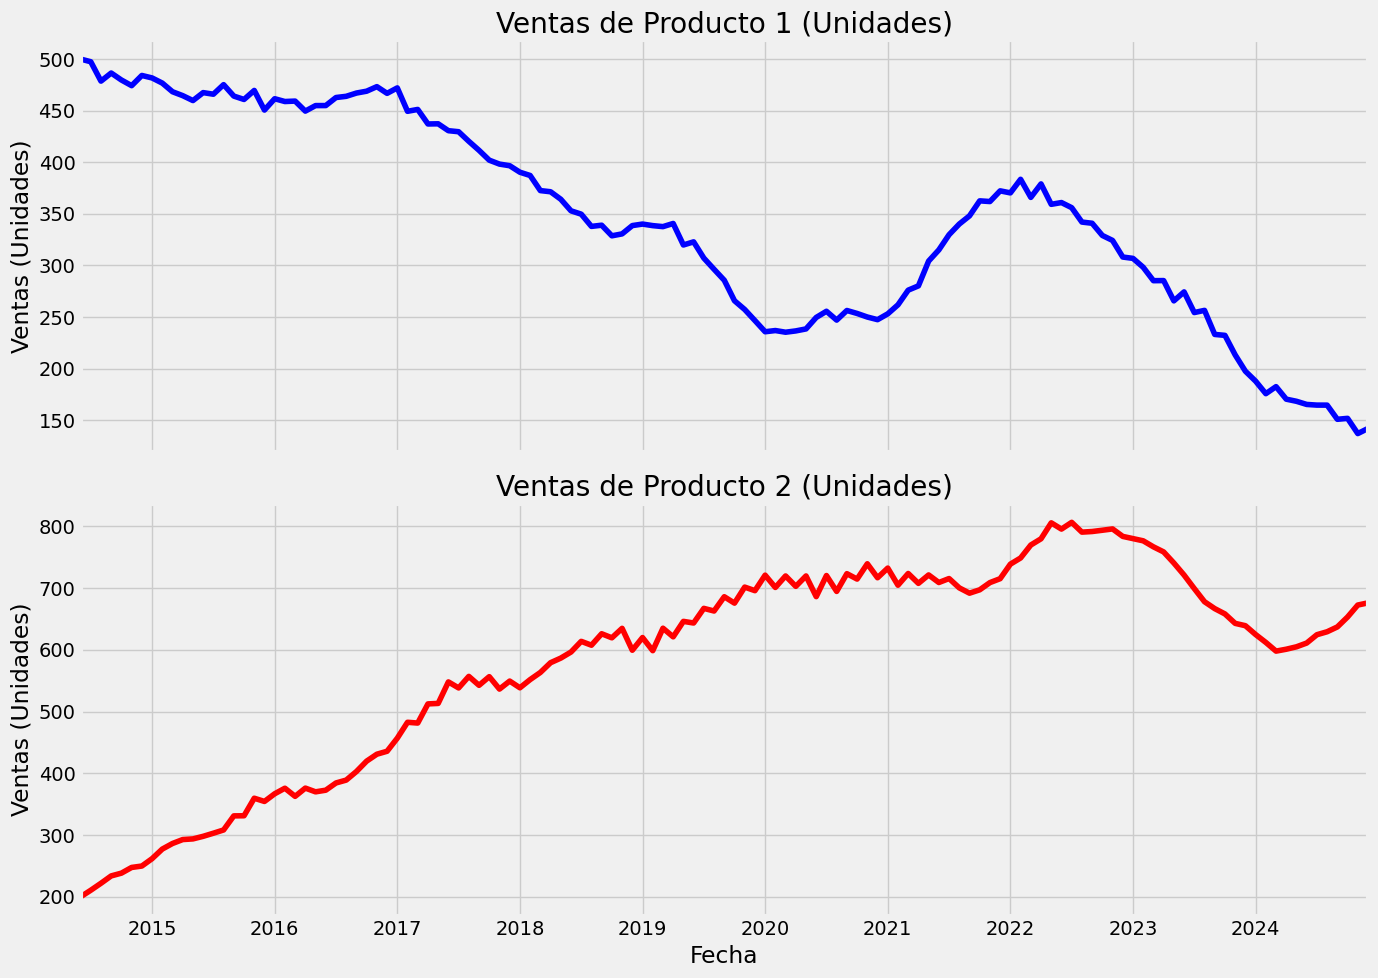

In [163]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(14, 10), sharex=True)

# Plot producto1
data['producto1'].plot(ax=axes[0], title='Ventas de Producto 1 (Unidades)', color='blue')
axes[0].set_ylabel('Ventas (Unidades)')
axes[0].grid(True)

# Plot producto2
data['producto2'].plot(ax=axes[1], title='Ventas de Producto 2 (Unidades)', color='red')
axes[1].set_xlabel('Fecha')
axes[1].set_ylabel('Ventas (Unidades)')
axes[1].grid(True)

plt.tight_layout()
plt.show()


## 3.2 Estadísticas Descriptivas

In [164]:
print('Estadísticas Descriptivas para Producto 1:')
print(data['producto1'].describe())
print('\nEstadísticas Descriptivas para Producto 2:')
print(data['producto2'].describe())


Estadísticas Descriptivas para Producto 1:
count    127.000000
mean     343.571660
std      100.234821
min      137.047639
25%      256.853812
50%      340.644019
75%      450.071775
max      500.000000
Name: producto1, dtype: float64

Estadísticas Descriptivas para Producto 2:
count    127.000000
mean     581.037664
std      167.504363
min      200.000000
25%      469.194001
50%      626.048401
75%      708.941718
max      806.440615
Name: producto2, dtype: float64


# 4. Analisis exploratorio de Componentes de una seríe de tiempo

In [165]:
producto_1 = data[['producto1']]
producto_1.index = data.index
# --------------------------------------
producto_2 = data[['producto2']]
producto_2.index = data.index

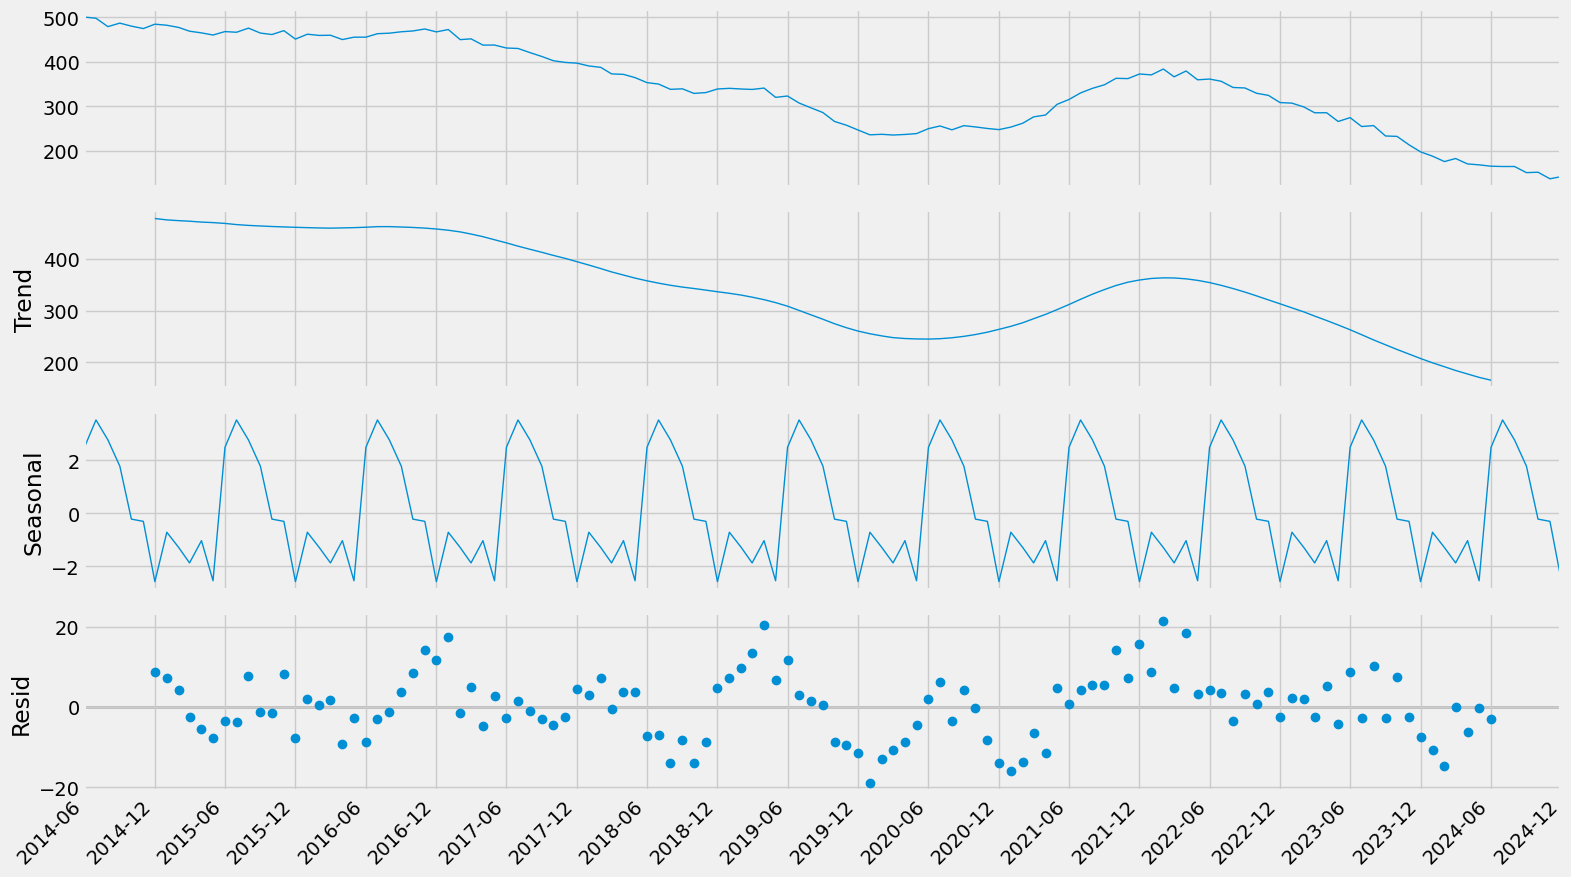

In [166]:
import matplotlib.dates as mdates

td_componentes = seasonal_decompose(producto_1, model="additive", period=12)
fig = td_componentes.plot()
fig.set_size_inches((16, 9))

# Iterate through each subplot to format the x-axis
for ax in fig.axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6)) # Show labels every 6 months
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m')) # Format as YYYY-MM
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right') # Rotate for better readability
    # Make lines thinner
    for line in ax.lines:
        line.set_linewidth(1.0) # Set linewidth to 1.0

fig.tight_layout()
plt.show()

Producto 2

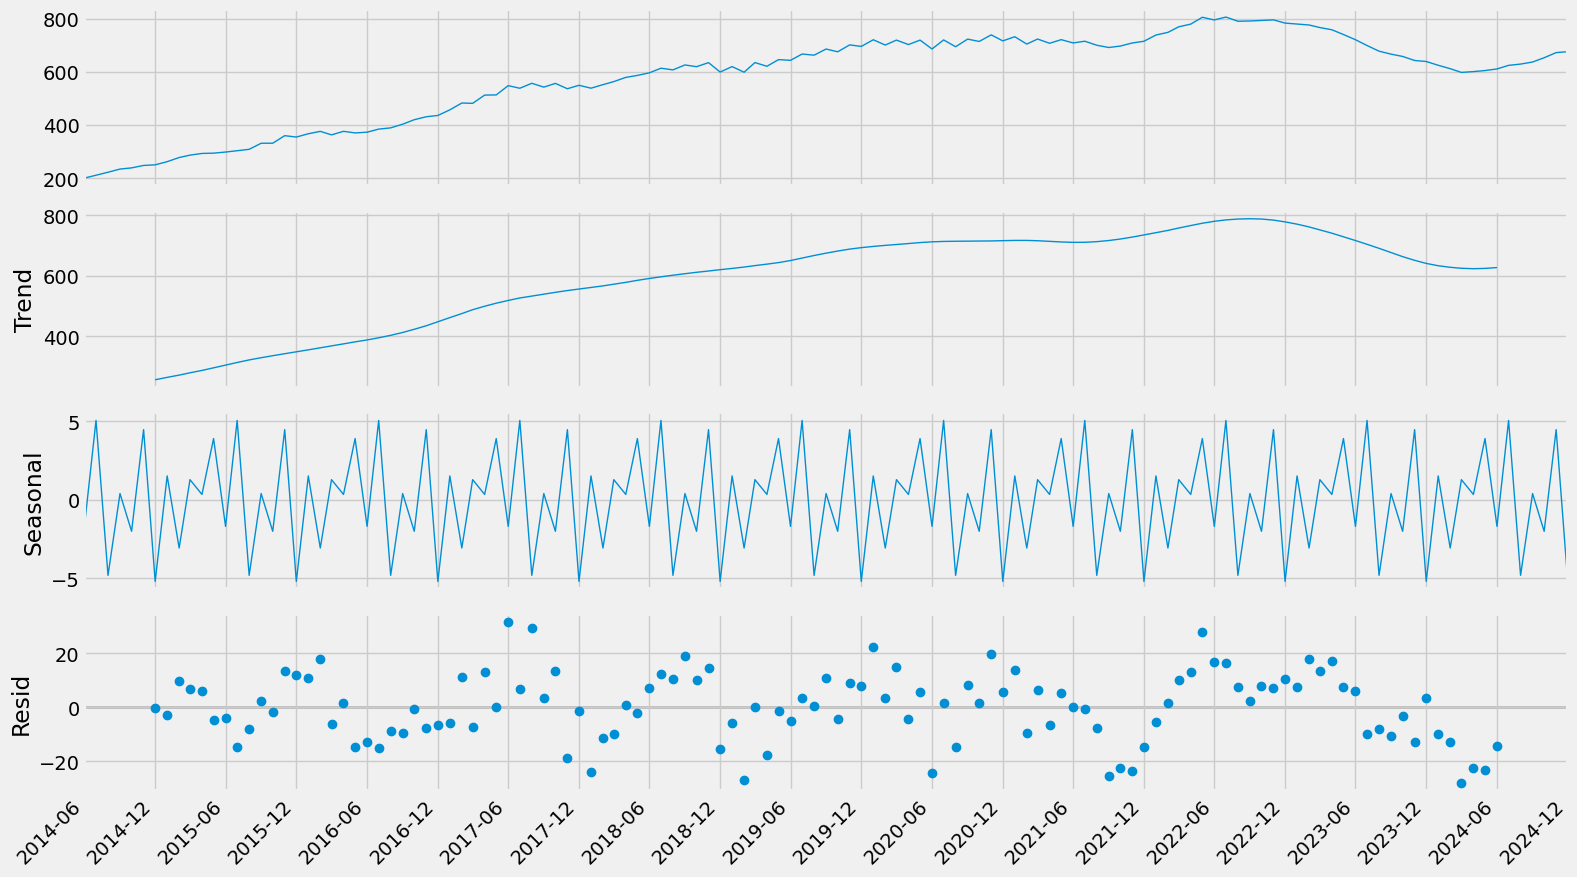

In [167]:
import matplotlib.dates as mdates

td_componentes_producto2 = seasonal_decompose(producto_2, model="additive", period=12)
fig_producto2 = td_componentes_producto2.plot()
fig_producto2.set_size_inches((16, 9))

# Iterate through each subplot to format the x-axis for producto2
for ax in fig_producto2.axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6)) # Show labels every 6 months
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m')) # Format as YYYY-MM
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right') # Rotate for better readability
    # Make lines thinner
    for line in ax.lines:
        line.set_linewidth(1.0) # Set linewidth to 1.0

fig_producto2.tight_layout()
plt.show()

# 5 . Protocolo de Evaluación

In [168]:
# iterations: El número de veces que se realizará el reentrenamiento del modelo o las iteraciones de la ventana deslizante para la evaluación.
iterations = 12

# train_size: El tamaño inicial del conjunto de entrenamiento.
train_size = data.shape[0] - iterations

# horizon: El número de pasos de tiempo a pronosticar en cada iteración.
horizon = 1

##5.1. Función protocolo de evaluación - Ventana Móvil

In [169]:

def rolling_window_evaluation(model_class, data, target_column, initial_train_size, num_iterations,
                              forecast_horizon=1, init_args=None, fit_args=None):
    """
    Evalúa un modelo usando ventana móvil (rolling window) sobre la serie de tiempo.
    Devuelve errores, pronósticos alineados y el mejor modelo según RMSE.
    """
    test_errors = []
    forecasts = []
    best_model = None
    lowest_error = float('inf')

    if init_args is None:
        init_args = {}
    if fit_args is None:
        fit_args = {}

    # Rolling window
    for i in range(num_iterations):
        train_window = data[target_column].iloc[i:i + initial_train_size]
        test_window = data[target_column].iloc[i + initial_train_size:i + initial_train_size + forecast_horizon]

        # Entrenar modelo
        model = model_class(train_window, **init_args)
        model_fit = model.fit(**fit_args)

        # Pronóstico
        test_predictions = model_fit.forecast(forecast_horizon)
        test_predictions = np.array(test_predictions).flatten()

        # Guardar pronóstico
        forecasts.append(test_predictions[0] if forecast_horizon == 1 else test_predictions)

        # Calcular RMSE
        test_error = np.sqrt(mean_squared_error(test_window, test_predictions))
        test_errors.append(test_error)

        # Guardar mejor modelo
        if test_error < lowest_error:
            lowest_error = test_error
            best_model = model_fit

    return test_errors, np.array(forecasts), best_model


##5.2. Se define función para graficar Valores Predichos

In [170]:

def plot_forecast_rolling(data, forecasts, initial_train_size, horizon=1, title_suffix=""):
    """
    Grafica la serie original y los pronósticos de ventana móvil.

    data: Serie original
    forecasts: Lista de pronósticos generados por ventana móvil
    initial_train_size: Tamaño de la ventana inicial
    horizon: Pasos de pronóstico por iteración
    """
    forecasts = np.array(forecasts).flatten()
    x_full = data.index if hasattr(data, 'index') else np.arange(len(data))

    # Crear índices alineados para cada forecast según ventana móvil
    forecast_indices = np.arange(initial_train_size, initial_train_size + len(forecasts)*horizon, horizon)

    fig, ax = plt.subplots(2, 1, figsize=(12, 10))

    # --- Gráfica completa ---
    ax[0].plot(x_full, data, label='Actual', color='blue')
    ax[0].plot(forecast_indices, forecasts, label='Forecast (Rolling)', color='orange', marker='o')
    ax[0].axvspan(forecast_indices[0], forecast_indices[-1], color='gray', alpha=0.2)
    ax[0].set_title(f'Actual Data with Rolling Forecast {title_suffix}')
    ax[0].legend()
    ax[0].grid(True)

    # --- Zoom en pronósticos ---
    actual_values = [data.iloc[i] for i in forecast_indices]  # valores reales alineados con pronósticos
    ax[1].plot(forecast_indices, actual_values, label='Actual (Zoomed)', color='blue', marker='o')
    ax[1].plot(forecast_indices, forecasts, label='Forecast (Zoomed)', color='orange', marker='o')

    # Líneas que muestran la diferencia entre real y forecast
    for i in range(len(forecasts)):
        ax[1].plot([forecast_indices[i], forecast_indices[i]],
                   [actual_values[i], forecasts[i]],
                   color='red', linestyle='--', linewidth=1.5)

    ax[1].set_title(f'Zoomed Rolling Forecast {title_suffix}')
    ax[1].legend()
    ax[1].grid(True)

    plt.tight_layout()
    plt.show()


#7. Modelos para los producto 1 y 2

##7.1. Modelos Promedio Móvil

### Definir clase Promedio Móvil

In [171]:
class MovingAverageModel:
    def __init__(self, endog, window):
        self.endog = endog
        self.window = window
        self.fittedvalues = None

    def fit(self):
        self.fittedvalues = self.endog.rolling(window=self.window).mean().dropna()
        return self

    def forecast(self, steps):
        last_window = self.endog.iloc[-self.window:]
        forecast_values = np.full(steps, last_window.mean())

        # Índice con fechas reales
        if isinstance(self.endog.index, pd.DatetimeIndex):
            forecast_index = pd.date_range(
                start=self.endog.index[-1] + pd.offsets.MonthBegin(),
                periods=steps,
                freq='MS'
            )
        else:
            forecast_index = pd.RangeIndex(start=len(self.endog), stop=len(self.endog)+steps)

        return pd.Series(forecast_values, index=forecast_index)


### Función para graficar pronósticos

In [172]:
def plot_forecast(data, forecasts, train_size, title_suffix="", rmse=None):
    forecasts = np.array(forecasts)
    fig, ax = plt.subplots(2, 1, figsize=(12, 10))

    x_full = data.index if hasattr(data, 'index') else range(len(data))

    # Gráfico completo
    ax[0].plot(x_full, data, label='Actual Data', color='blue')
    forecast_indices = x_full[train_size:train_size+len(forecasts)]
    ax[0].plot(forecast_indices, forecasts, label='Forecast', color='orange')
    ax[0].axvspan(forecast_indices[0], forecast_indices[-1], color='gray', alpha=0.2)
    title0 = f'Actual Data with Forecast Overlay {title_suffix}'
    if rmse is not None:
        title0 += f' (RMSE: {rmse:.3f})'
    ax[0].set_title(title0)
    ax[0].set_xlabel('Time')
    ax[0].set_ylabel('Value')
    ax[0].legend()
    ax[0].grid(True)

    # Zoom
    ax[1].plot(forecast_indices, data[train_size:train_size+len(forecasts)],
               label='Actual Data (Zoomed)', color='blue', marker='o')
    ax[1].plot(forecast_indices, forecasts,
               label='Forecast (Zoomed)', color='orange', marker='o')
    for i in range(len(forecasts)):
        ax[1].plot([forecast_indices[i], forecast_indices[i]],
                   [data[train_size+i], forecasts[i]],
                   color='#ff4d4d', linestyle='--', linewidth=1.5)

    title1 = f'Zoomed-In Forecast Section {title_suffix}'
    if rmse is not None:
        title1 += f' (RMSE: {rmse:.3f})'
    ax[1].set_title(title1)
    ax[1].set_xlabel('Time')
    ax[1].set_ylabel('Value')
    ax[1].legend()
    ax[1].grid(True)
    plt.tight_layout()
    plt.show()

### Ejecutar para Producto 1 y 2

Producto 1 - RMSE Promedio: 7.925840645833333


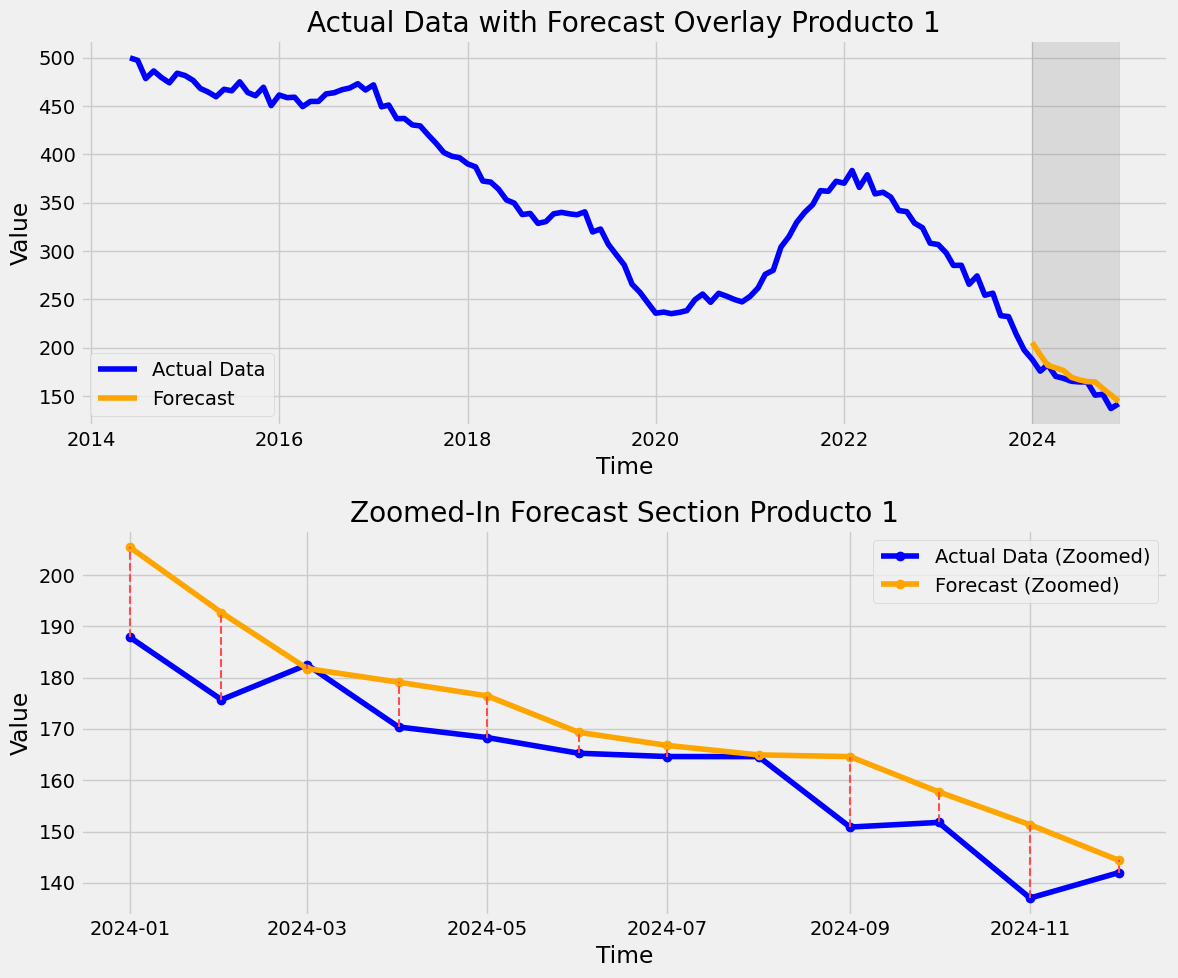

Producto 2 - RMSE Promedio: 14.409853479166676


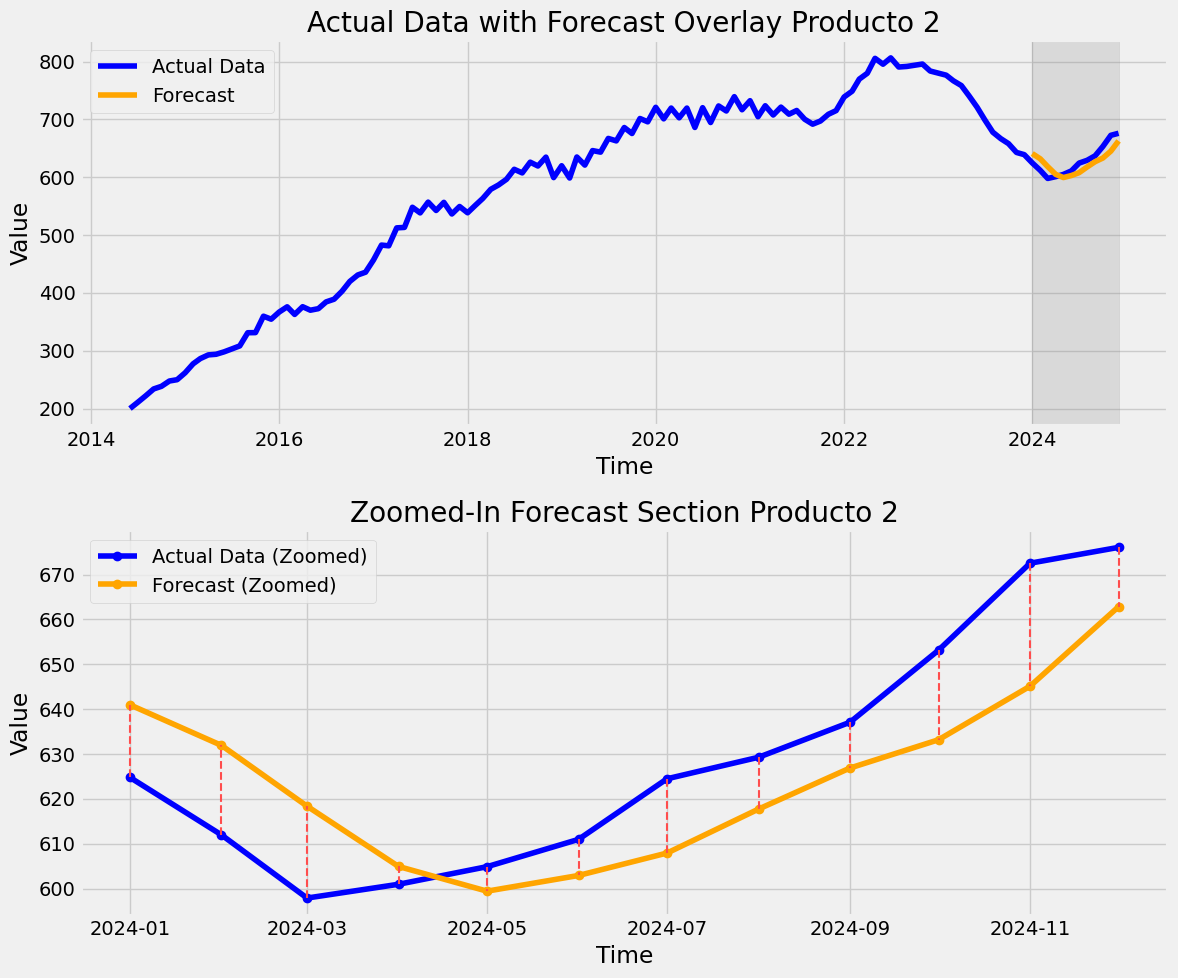

In [173]:
# Producto 1
ma_test_errors_1, ma_forecasts_1, ma_model_1 = rolling_window_evaluation(
    model_class=MovingAverageModel,
    data=data,
    target_column='producto1',
    initial_train_size=train_size,
    num_iterations=iterations,
    forecast_horizon=horizon,
    init_args={'window': 2}
)
print("Producto 1 - RMSE Promedio:", np.mean(ma_test_errors_1))
plot_forecast(data['producto1'], ma_forecasts_1, train_size, title_suffix="Producto 1")

# Producto 2
ma_test_errors_2, ma_forecasts_2, ma_model_2 = rolling_window_evaluation(
    model_class=MovingAverageModel,
    data=data,
    target_column='producto2',
    initial_train_size=train_size,
    num_iterations=iterations,
    forecast_horizon=horizon,
    init_args={'window': 2}
)
print("Producto 2 - RMSE Promedio:", np.mean(ma_test_errors_2))
plot_forecast(data['producto2'], ma_forecasts_2, train_size, title_suffix="Producto 2")


In [174]:
# Función para evaluar diferentes ventanas de promedio móvil
def evaluate_ma_windows(data, target_column, train_size, iterations, horizon, max_window=12):
    results = []

    for w in range(1, max_window + 1):
        ma_test_errors, _, _ = rolling_window_evaluation(
            model_class=MovingAverageModel,
            data=data,
            target_column=target_column,
            initial_train_size=train_size,
            num_iterations=iterations,
            forecast_horizon=horizon,
            init_args={'window': w}
        )
        rmse = np.mean(ma_test_errors)
        results.append([w, rmse])

    # Crear DataFrame
    df_results = pd.DataFrame(results, columns=["Window", "RMSE"])
    return df_results

# Obtener tabla para Producto 1
tabla_p1 = evaluate_ma_windows(
    data=data,
    target_column='producto1',
    train_size=train_size,
    iterations=iterations,
    horizon=horizon,
    max_window=6
)

# Obtener tabla para Producto 2
tabla_p2 = evaluate_ma_windows(
    data=data,
    target_column='producto2',
    train_size=train_size,
    iterations=iterations,
    horizon=horizon,
    max_window=6
)

print("Resultados Producto 1:")
print(tabla_p1)

print("\nResultados Producto 2:")
print(tabla_p2)


Resultados Producto 1:
   Window       RMSE
0       1   6.736352
1       2   7.925841
2       3  11.095424
3       4  14.455593
4       5  18.002011
5       6  21.612236

Resultados Producto 2:
   Window       RMSE
0       1   9.940737
1       2  14.409853
2       3  18.494472
3       4  22.335978
4       5  25.728828
5       6  29.004547


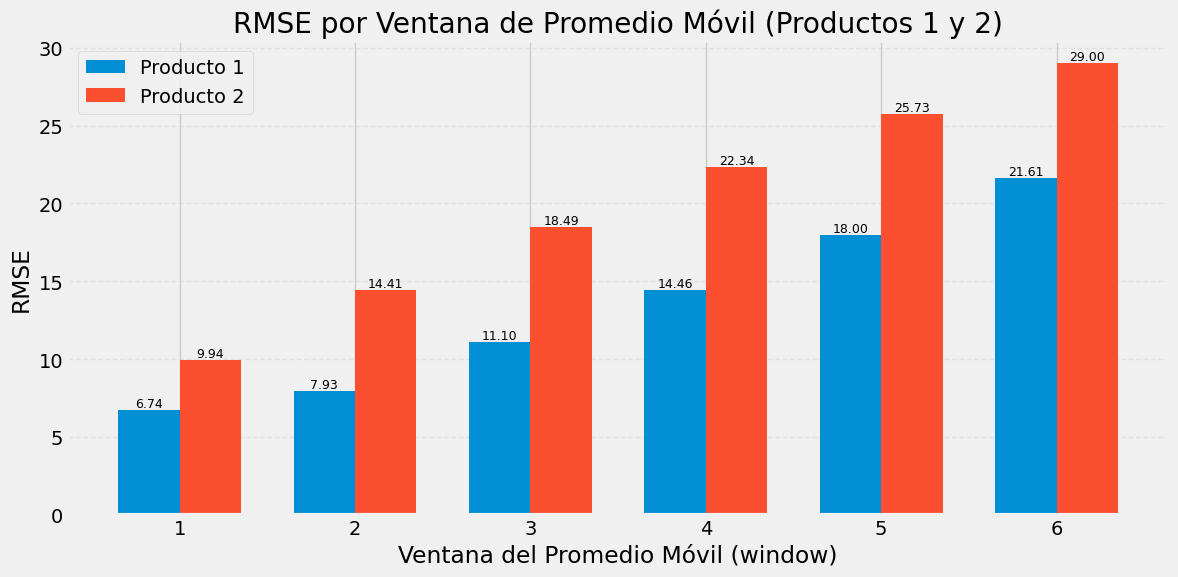

In [175]:
import numpy as np
import matplotlib.pyplot as plt

# Aseguramos que ambas tablas tengan la columna Window alineada
windows = tabla_p1["Window"]

# Valores de RMSE
rmse_p1 = tabla_p1["RMSE"]
rmse_p2 = tabla_p2["RMSE"]

# Posiciones de las barras
x = np.arange(len(windows))
width = 0.35  # Ancho de cada barra

plt.figure(figsize=(12, 6))

# Dibujar barras
bars1 = plt.bar(x - width/2, rmse_p1, width, label='Producto 1')
bars2 = plt.bar(x + width/2, rmse_p2, width, label='Producto 2')

# Añadir valores encima de las barras
for bar in bars1:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,   # posición X centrada
        height,                            # posición Y en la punta
        f"{height:.2f}",                   # formato del RMSE
        ha='center', va='bottom', fontsize=9
    )

for bar in bars2:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.2f}",
        ha='center', va='bottom', fontsize=9
    )

# Configuración estética
plt.title("RMSE por Ventana de Promedio Móvil (Productos 1 y 2)")
plt.xlabel("Ventana del Promedio Móvil (window)")
plt.ylabel("RMSE")
plt.xticks(x, windows)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()

plt.show()


## 7.2. SES, Holt y Holt-Winters

###Separar correctamente los datasets por producto (mensual)

In [176]:
# Separar los datasets por producto
data_producto1 = data[['producto1']].copy()
data_producto2 = data[['producto2']].copy()

# Asegurar índice mensual
data_producto1.index = pd.date_range(start=data.index[0], periods=len(data_producto1), freq='MS')
data_producto2.index = pd.date_range(start=data.index[0], periods=len(data_producto2), freq='MS')

print(data_producto1.head())
print(data_producto2.head())


             producto1
2014-06-01  500.000000
2014-07-01  497.400893
2014-08-01  478.605317
2014-09-01  486.454125
2014-10-01  479.695678
             producto2
2014-06-01  200.000000
2014-07-01  210.686220
2014-08-01  222.018584
2014-09-01  233.920990
2014-10-01  238.402098


###Clase ETS genérica

In [177]:
class ETSModel:
    def __init__(self, endog, error='add', trend=None, seasonal=None, seasonal_periods=None):
        self.endog = endog
        self.error = error
        self.trend = trend
        self.seasonal = seasonal
        self.seasonal_periods = seasonal_periods
        self.model_fit = None

    def fit(self, smoothing_level=None, smoothing_trend=None, smoothing_seasonal=None, optimized=True):
        self.model_fit = ExponentialSmoothing(
            self.endog,
            trend=self.trend,
            seasonal=self.seasonal,
            seasonal_periods=self.seasonal_periods
        ).fit(
            smoothing_level=smoothing_level,
            smoothing_trend=smoothing_trend,
            smoothing_seasonal=smoothing_seasonal,
            optimized=optimized
        )
        return self

    def forecast(self, steps):
        return self.model_fit.forecast(steps)


### Función de evaluación con ventana móvil y Bayes

In [178]:
def train_and_evaluate_RMSE_bayes(error, trend, seasonal, alpha, beta, gamma, data_series, target_column, train_size, iterations, horizon):
    # Map numeric values to actual strings
    error_map = ["add", "mul"]
    trend_map = [None, "add", "mul"]
    seasonal_map = [None, "add", "mul"]

    error_val = error_map[int(round(error))]
    trend_val = trend_map[int(round(trend))]
    seasonal_val = seasonal_map[int(round(seasonal))]

    init_args = {
        'error': error_val,
        'trend': trend_val,
        'seasonal': seasonal_val,
        'seasonal_periods': 12  # Mensual
    }

    fit_args = {
        'smoothing_level': float(alpha),
        'smoothing_trend': float(beta) if trend_val else None,
        'smoothing_seasonal': float(gamma) if seasonal_val else None
    }

    test_errors, forecasts, _ = rolling_window_evaluation(
        model_class=ETSModel,
        data=data_series,
        target_column=target_column,
        initial_train_size=train_size,
        num_iterations=iterations,
        forecast_horizon=horizon,
        init_args=init_args,
        fit_args=fit_args
    )

    avg_rmse = np.mean(test_errors)
    print(f"RMSE={avg_rmse:.4f}, Error={error_val}, Trend={trend_val}, Seasonal={seasonal_val}, alpha={alpha:.2f}, beta={beta:.2f}, gamma={gamma:.2f}")

    return -avg_rmse  # Negativo para Bayes


### Definir parámetros para Bayes

In [179]:
pbounds = {
    'error': (0, 1),        # 0->add, 1->mul
    'trend': (0, 2),        # 0->None, 1->add, 2->mul
    'seasonal': (0, 2),     # 0->None, 1->add, 2->mul
    'alpha': (0.01, 0.99),
    'beta': (0.01, 0.99),
    'gamma': (0.01, 0.99)
}


### Ejecutar Bayes para cada producto

In [180]:
# Parámetros generales
train_size = len(data_producto1) - 12
iterations = 12
horizon = 1

# Producto 1
optimizer_p1 = BayesianOptimization(
    f=lambda error, trend, seasonal, alpha, beta, gamma: train_and_evaluate_RMSE_bayes(
        error, trend, seasonal, alpha, beta, gamma,
        data_producto1, 'producto1', train_size, iterations, horizon
    ),
    pbounds=pbounds,
    random_state=42,
    verbose=2
)
optimizer_p1.maximize(init_points=10, n_iter=20)
best_result_p1 = optimizer_p1.max

# Producto 2
optimizer_p2 = BayesianOptimization(
    f=lambda error, trend, seasonal, alpha, beta, gamma: train_and_evaluate_RMSE_bayes(
        error, trend, seasonal, alpha, beta, gamma,
        data_producto2, 'producto2', train_size, iterations, horizon
    ),
    pbounds=pbounds,
    random_state=42,
    verbose=2
)
optimizer_p2.maximize(init_points=10, n_iter=20)
best_result_p2 = optimizer_p2.max


|   iter    |  target   |   error   |   trend   | seasonal  |   alpha   |   beta    |   gamma   |
-------------------------------------------------------------------------------------------------
RMSE=7.2550, Error=add, Trend=mul, Seasonal=add, alpha=0.60, beta=0.16, gamma=0.16
| 1         | -7.254966 | 0.3745401 | 1.9014286 | 1.4639878 | 0.5966853 | 0.1628982 | 0.1628746 |
RMSE=9.7329, Error=add, Trend=mul, Seasonal=add, alpha=0.70, beta=0.03, gamma=0.96
| 2         | -9.732875 | 0.0580836 | 1.7323522 | 1.2022300 | 0.7039111 | 0.0301728 | 0.9605116 |
RMSE=36.6918, Error=mul, Trend=None, Seasonal=None, alpha=0.19, beta=0.31, gamma=0.52
| 3         | -36.69183 | 0.8324426 | 0.4246782 | 0.3636499 | 0.1897364 | 0.3081573 | 0.5242613 |
RMSE=13.4387, Error=add, Trend=add, Seasonal=add, alpha=0.15, beta=0.30, gamma=0.37
| 4         | -13.43867 | 0.4319450 | 0.5824582 | 1.2237057 | 0.1467039 | 0.2963017 | 0.3690346 |
RMSE=5.5212, Error=add, Trend=mul, Seasonal=None, alpha=0.51, beta=0.59, gam

### Crear tabla comparativa de los mejores RMSE

In [181]:
def extract_best_params(best_result):
    params = best_result['params']
    error_map = ["add", "mul"]
    trend_map = [None, "add", "mul"]
    seasonal_map = [None, "add", "mul"]
    return {
        "Error": error_map[int(round(params['error']))],
        "Trend": trend_map[int(round(params['trend']))],
        "Seasonal": seasonal_map[int(round(params['seasonal']))],
        "RMSE": -best_result['target']
    }

df_comparativa = pd.DataFrame({
    "Producto": ["Producto 1", "Producto 2"],
    **pd.DataFrame([extract_best_params(best_result_p1), extract_best_params(best_result_p2)])
})

print(df_comparativa)


     Producto Error Trend Seasonal      RMSE
0  Producto 1   add   mul     None  5.426490
1  Producto 2   add   add     None  6.927364


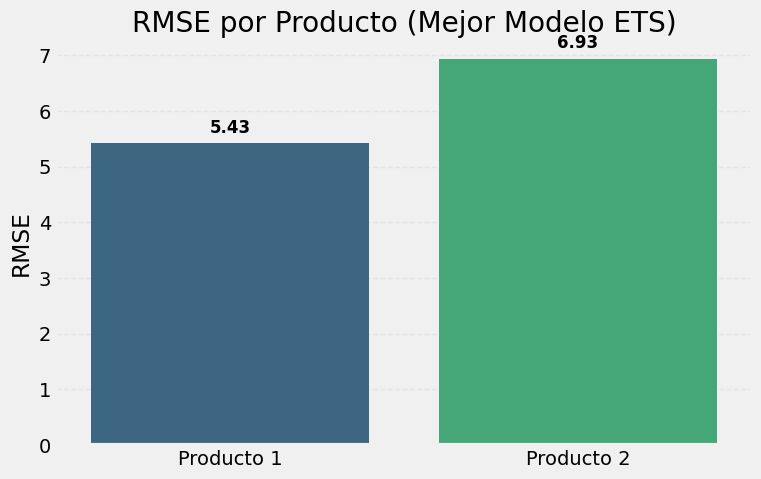

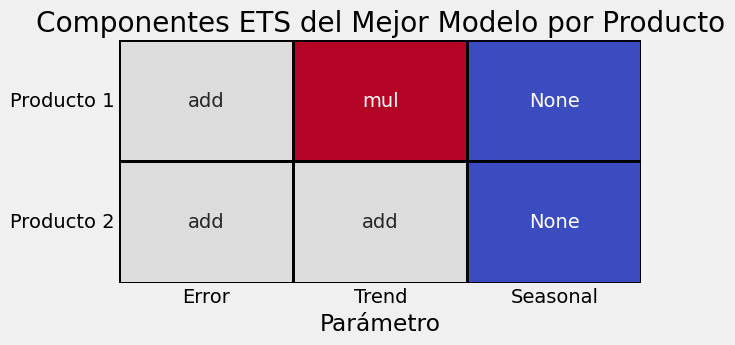

In [182]:
import matplotlib.pyplot as plt
import seaborn as sns

# ================================
# 1) GRÁFICO DE BARRAS DEL RMSE
# ================================

plt.figure(figsize=(8,5))
ax = sns.barplot(
    data=df_comparativa,
    x="Producto",
    y="RMSE",
    palette="viridis"
)

# Mostrar valores del RMSE encima de cada barra
for i, bar in enumerate(ax.patches):
    altura = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        altura + (altura * 0.02),       # posición un poco arriba
        f"{altura:.2f}",                # mostrar RMSE con 2 decimales
        ha='center',
        va='bottom',
        fontsize=12,
        fontweight='bold'
    )

plt.title("RMSE por Producto (Mejor Modelo ETS)")
plt.ylabel("RMSE")
plt.xlabel("")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.show()


# ============================================
# 2) TABLA VISUAL (Heatmap) DE LOS COMPONENTES ETS
# ============================================

df_cat = df_comparativa[["Error", "Trend", "Seasonal"]]
df_cat_numeric = df_cat.apply(lambda col: col.astype('category').cat.codes)

plt.figure(figsize=(6,3))
ax = sns.heatmap(
    df_cat_numeric,
    annot=df_cat,         # mostrar etiquetas reales
    fmt="",
    cmap="coolwarm",
    cbar=False,
    linewidths=1,
    linecolor="black"
)

ax.set_title("Componentes ETS del Mejor Modelo por Producto")
ax.set_yticklabels(df_comparativa["Producto"], rotation=0)
plt.xlabel("Parámetro")
plt.show()


### Extraer mejores parámetros del optimizador p1

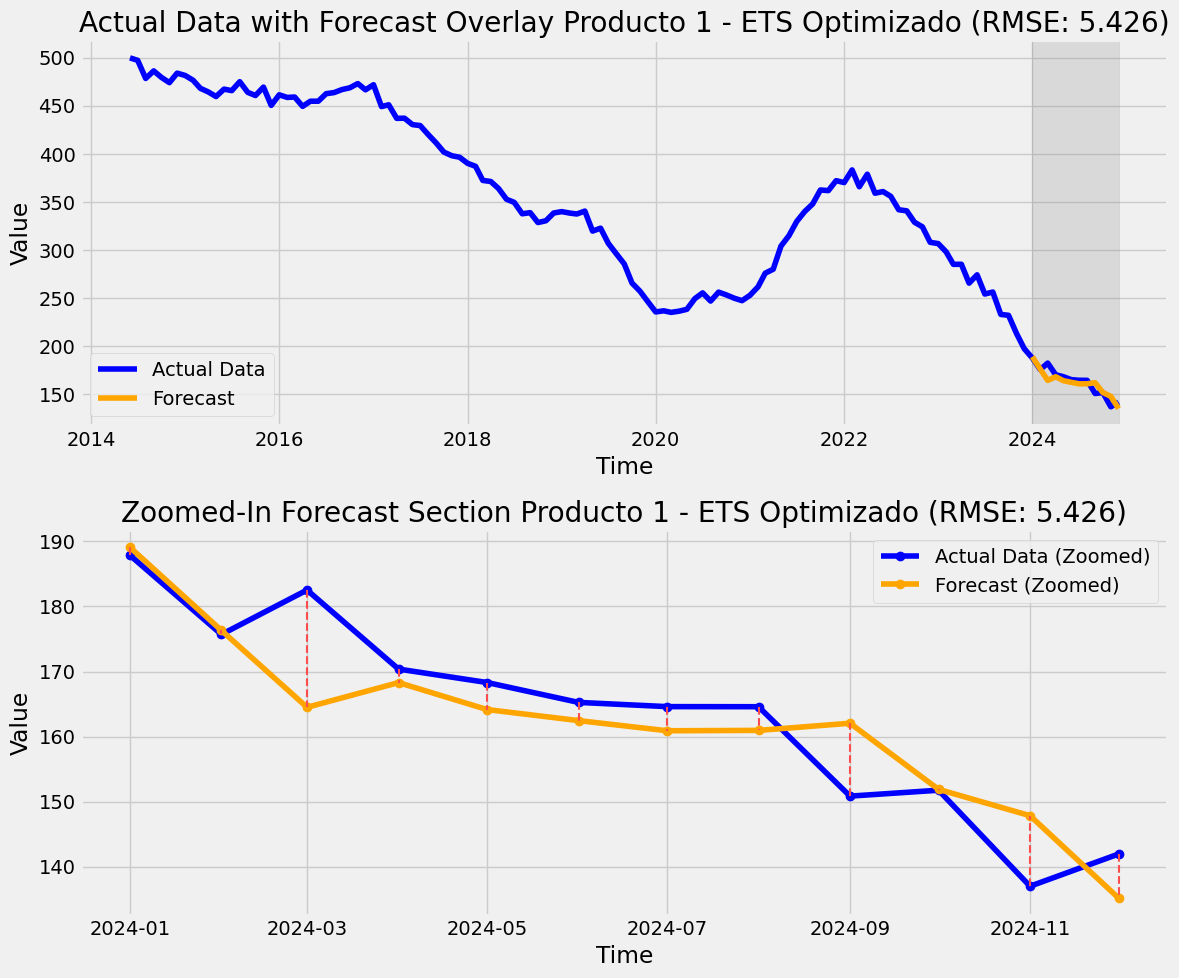

In [183]:
# Extraer mejores parámetros del optimizador p1
params_p1 = optimizer_p1.max['params']

error_map = ["add", "mul"]
trend_map = [None, "add", "mul"]
seasonal_map = [None, "add", "mul"]

best_error_p1 = error_map[int(round(params_p1['error']))]
best_trend_p1 = trend_map[int(round(params_p1['trend']))]
best_seasonal_p1 = seasonal_map[int(round(params_p1['seasonal']))]

best_alpha_p1 = params_p1['alpha']
best_beta_p1 = params_p1['beta'] if best_trend_p1 else None
best_gamma_p1 = params_p1['gamma'] if best_seasonal_p1 else None

final_init_p1 = {
    'error': best_error_p1,
    'trend': best_trend_p1,
    'seasonal': best_seasonal_p1,
    'seasonal_periods': 12
}

final_fit_p1 = {
    'smoothing_level': best_alpha_p1,
    'smoothing_trend': best_beta_p1,
    'smoothing_seasonal': best_gamma_p1
}

# Generar forecasts con ventana móvil
_, forecasts_p1, _ = rolling_window_evaluation(
    model_class=ETSModel,
    data=data_producto1,
    target_column='producto1',
    initial_train_size=train_size,
    num_iterations=iterations,
    forecast_horizon=horizon,
    init_args=final_init_p1,
    fit_args=final_fit_p1
)

# Obtener el RMSE del mejor modelo ETS para Producto 1
rmse_ets_producto1 = -optimizer_p1.max['target']

# Graficar
plot_forecast(
    data_producto1['producto1'],
    forecasts_p1,
    train_size,
    title_suffix="Producto 1 - ETS Optimizado",
    rmse=rmse_ets_producto1
)

### Extraer mejores parámetros del optimizador p2

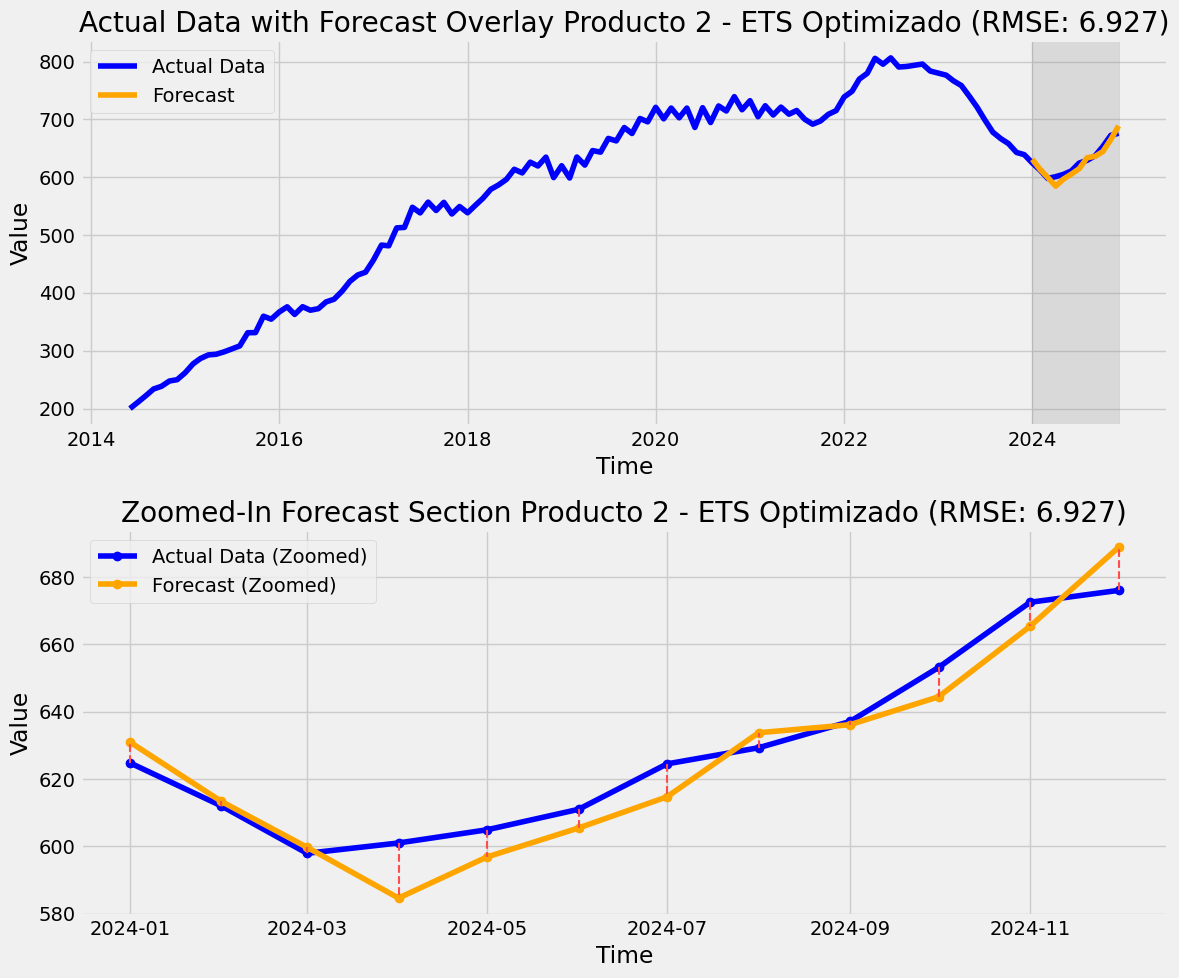

In [184]:
# Extraer mejores parámetros del optimizador p2
params_p2 = optimizer_p2.max['params']

best_error_p2 = error_map[int(round(params_p2['error']))]
best_trend_p2 = trend_map[int(round(params_p2['trend']))]
best_seasonal_p2 = seasonal_map[int(round(params_p2['seasonal']))]

best_alpha_p2 = params_p2['alpha']
best_beta_p2 = params_p2['beta'] if best_trend_p2 else None
best_gamma_p2 = params_p2['gamma'] if best_seasonal_p2 else None

final_init_p2 = {
    'error': best_error_p2,
    'trend': best_trend_p2,
    'seasonal': best_seasonal_p2,
    'seasonal_periods': 12
}

final_fit_p2 = {
    'smoothing_level': best_alpha_p2,
    'smoothing_trend': best_beta_p2,
    'smoothing_seasonal': best_gamma_p2
}

# Generar forecasts con ventana móvil
_, forecasts_p2, _ = rolling_window_evaluation(
    model_class=ETSModel,
    data=data_producto2,
    target_column='producto2',
    initial_train_size=train_size,
    num_iterations=iterations,
    forecast_horizon=horizon,
    init_args=final_init_p2,
    fit_args=final_fit_p2
)

# Obtener el RMSE del mejor modelo ETS para Producto 2
rmse_ets_producto2 = -optimizer_p2.max['target']

# Graficar
plot_forecast(
    data_producto2['producto2'],
    forecasts_p2,
    train_size,
    title_suffix="Producto 2 - ETS Optimizado",
    rmse=rmse_ets_producto2
)

## 7.3. Modelos de Regresión con Tendencia y Estacionalidad

In [185]:
# Asegurarse de que los datos sean numéricos y no tengan NaNs
data_producto1 = data[['producto1']].copy().astype(float)
data_producto2 = data[['producto2']].copy().astype(float)

# Imputar o interpolar NaNs si existen
data_producto1['producto1'] = data_producto1['producto1'].interpolate()
data_producto2['producto2'] = data_producto2['producto2'].interpolate()

# Índice mensual
data_producto1.index = pd.date_range(start=data_producto1.index[0], periods=len(data_producto1), freq='MS')
data_producto2.index = pd.date_range(start=data_producto2.index[0], periods=len(data_producto2), freq='MS')


In [186]:
class PolynomialRegressionSeasonalModel:
    def __init__(self, endog, degree, seasonal_periods):
        self.endog = endog.astype(float)
        self.degree = degree
        self.seasonal_periods = seasonal_periods

        self.model = None
        self.poly = PolynomialFeatures(degree=self.degree)
        self.fittedvalues = None

        # Crear estructura fija de dummies estacionales
        # Los índices de mes van de 0 a seasonal_periods-1
        self.seasonal_dummies_template = pd.get_dummies(
            np.arange(self.seasonal_periods) % self.seasonal_periods,
            drop_first=False
        )

    def _create_design_matrix(self, y_train, future_steps=None):

        if future_steps is None:  # Para fit (usar train_window)
            n = len(y_train)
            time_index_raw = np.arange(n).reshape(-1, 1)
            season_index_raw = np.arange(n) % self.seasonal_periods

        else:  # Para forecast (extender el índice de tiempo)
            # El inicio del índice de tiempo para el pronóstico debe continuar desde el final del entrenamiento
            start_time_idx = len(self.endog) # len(self.endog) es la longitud del train_window con el que se inicializó el modelo
            n = future_steps
            time_index_raw = np.arange(start_time_idx, start_time_idx + n).reshape(-1, 1)
            season_index_raw = np.arange(start_time_idx, start_time_idx + n) % self.seasonal_periods

        # Tendencia polinómica
        poly_features = self.poly.fit_transform(time_index_raw)

        # Dummies estacionales
        seasonality = pd.get_dummies(season_index_raw, drop_first=False)

        # Asegurarse de que las columnas de estacionalidad coincidan con el template
        # Esto es crucial para que los dummies siempre tengan el mismo número y orden de columnas
        seasonality = seasonality.reindex(
            columns=self.seasonal_dummies_template.columns,
            fill_value=0
        )

        # Matriz final
        # Se usa LinearRegression(fit_intercept=False) porque PolynomialFeatures ya añade el intercepto.
        X = np.hstack([poly_features, seasonality.values]).astype(float)

        return X

    def fit(self):
        X_train = self._create_design_matrix(self.endog) # self.endog es el train_window

        # Importante: fit_intercept=False porque PolynomialFeatures ya incluye el intercepto
        self.model = LinearRegression(fit_intercept=False).fit(X_train, self.endog.values)
        self.fittedvalues = pd.Series(self.model.predict(X_train), index=self.endog.index)

        return self

    def forecast(self, steps):
        X_future = self._create_design_matrix(self.endog, future_steps=steps)
        forecast_values = self.model.predict(X_future)

        # Generar un índice de fecha para los pronósticos
        if isinstance(self.endog.index, pd.DatetimeIndex):
            last_date = self.endog.index[-1]
            # Usar MonthEnd para asegurar que siempre sea el final del mes, o MonthBegin si es el principio
            forecast_index = pd.date_range(start=last_date + pd.offsets.MonthBegin(1), periods=steps, freq='MS')
        else:
            last_index = self.endog.index[-1]
            forecast_index = pd.RangeIndex(start=last_index + 1, stop=last_index + 1 + steps)

        return pd.Series(forecast_values, index=forecast_index)

In [187]:
def evaluate_polynomial_model(data_series, target_col, max_degree=12, seasonal_periods=12):
    best_forecasts = None
    best_rmse = None
    best_degree = None
    rmses = []

    for degree in range(1, max_degree + 1):
        print(f"\nEvaluando grado {degree} para {target_col}...")

        test_errors, forecasts, model = rolling_window_evaluation(
            model_class=lambda y, deg=degree: PolynomialRegressionSeasonalModel(
                endog=y.fillna(method='ffill'),
                degree=deg,
                seasonal_periods=seasonal_periods
            ),
            data=data_series,
            target_column=target_col,
            initial_train_size=train_size,
            num_iterations=iterations,
            forecast_horizon=horizon
        )

        rmse = np.sqrt(np.mean(test_errors))
        rmses.append(rmse)

        if best_rmse is None or rmse < best_rmse:
            best_rmse = rmse
            best_forecasts = forecasts
            best_degree = degree

        print(f"Grado {degree} → RMSE: {rmse:.4f}")

    return best_degree, best_rmse, best_forecasts, rmses


In [188]:
productos = {
    "producto1": data_producto1,
    "producto2": data_producto2
}

resultados_polynomial = {}

for target, df_prod in productos.items():
    print("\n====================================")
    print(f"MODELOS POLINOMIALES → {target}")
    print("====================================")

    best_degree, best_rmse, best_forecasts, rmses = evaluate_polynomial_model(
        df_prod, target_col=target, max_degree=12, seasonal_periods=12
    )

    resultados_polynomial[target] = {
        "best_degree": best_degree,
        "best_rmse": best_rmse,
        "forecasts": best_forecasts,
        "all_rmses": rmses
    }

    print(f"\nMejor grado para {target}: {best_degree} con RMSE={best_rmse:.4f}")



MODELOS POLINOMIALES → producto1

Evaluando grado 1 para producto1...
Grado 1 → RMSE: 7.5494

Evaluando grado 2 para producto1...
Grado 2 → RMSE: 9.5281

Evaluando grado 3 para producto1...
Grado 3 → RMSE: 8.2339

Evaluando grado 4 para producto1...
Grado 4 → RMSE: 7.6998

Evaluando grado 5 para producto1...
Grado 5 → RMSE: 9.5723

Evaluando grado 6 para producto1...
Grado 6 → RMSE: 5.4685

Evaluando grado 7 para producto1...
Grado 7 → RMSE: 11.0568

Evaluando grado 8 para producto1...
Grado 8 → RMSE: 12.9348

Evaluando grado 9 para producto1...
Grado 9 → RMSE: 15.2916

Evaluando grado 10 para producto1...
Grado 10 → RMSE: 19.3909

Evaluando grado 11 para producto1...
Grado 11 → RMSE: 19.1378

Evaluando grado 12 para producto1...
Grado 12 → RMSE: 18.5987

Mejor grado para producto1: 6 con RMSE=5.4685

MODELOS POLINOMIALES → producto2

Evaluando grado 1 para producto2...
Grado 1 → RMSE: 14.5767

Evaluando grado 2 para producto2...
Grado 2 → RMSE: 7.8110

Evaluando grado 3 para producto

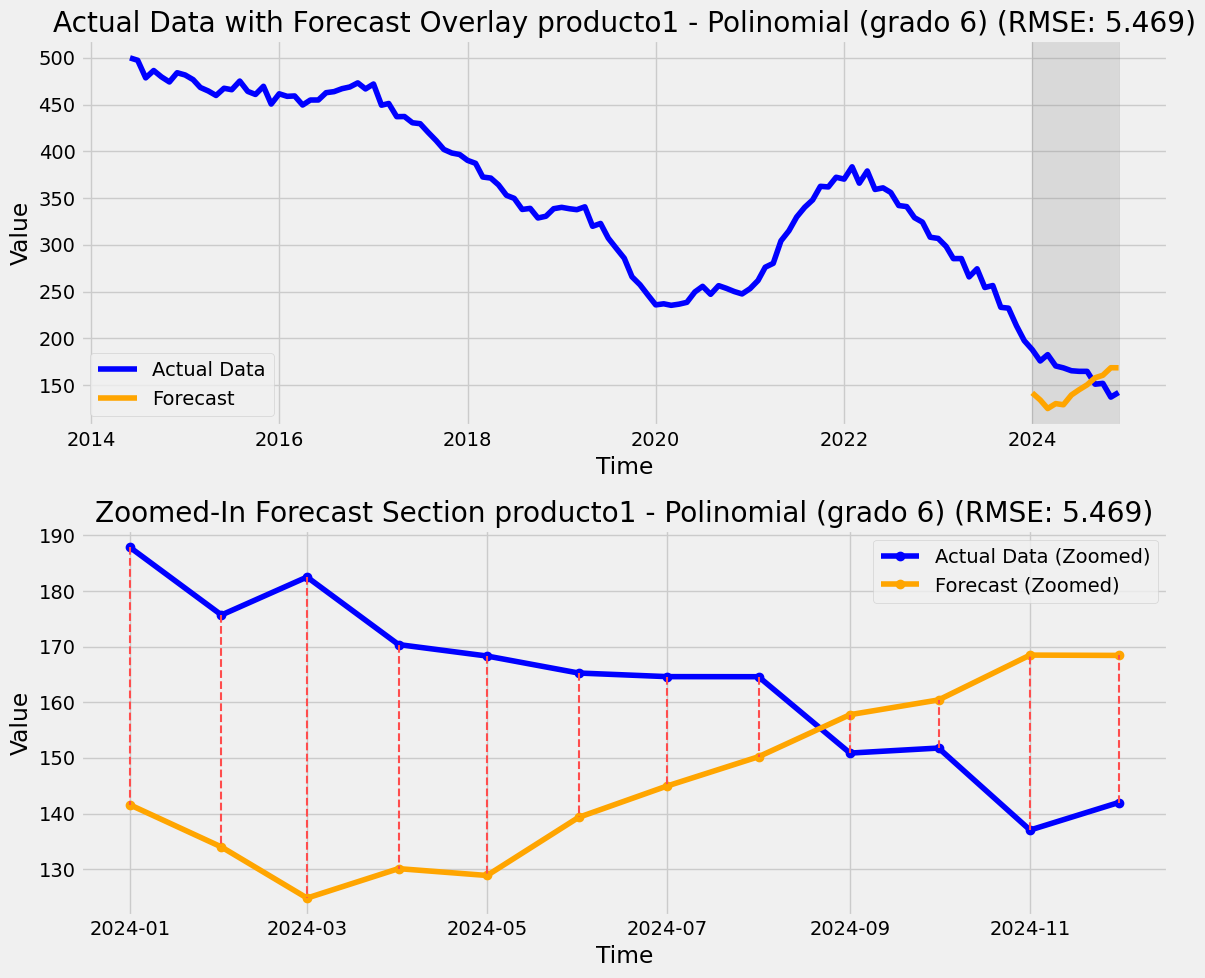

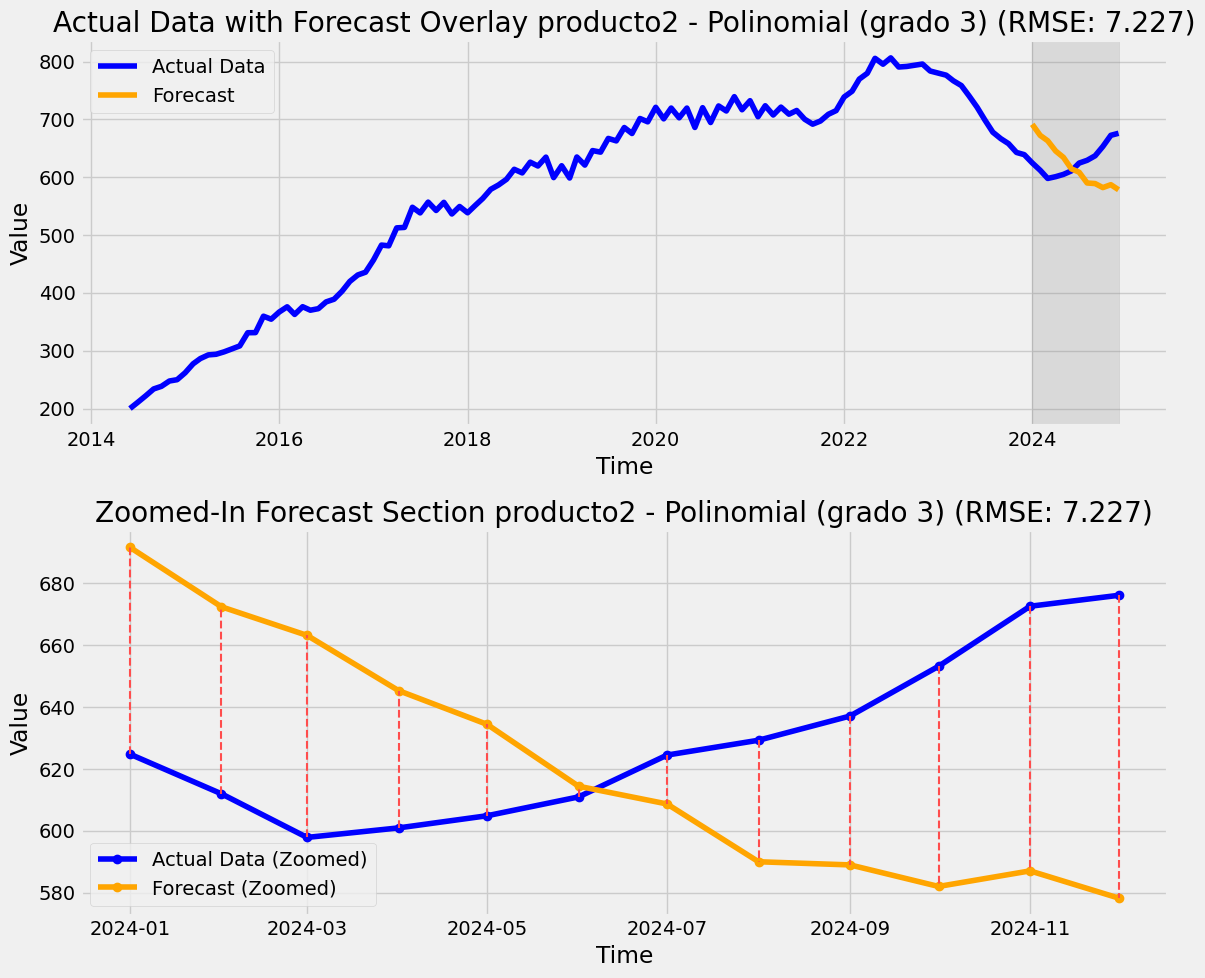

In [189]:
for target, result_data in resultados_polynomial.items():
    forecasts = result_data["forecasts"]
    best_rmse = result_data["best_rmse"]
    best_degree = result_data["best_degree"]

    plot_forecast(
        productos[target][target],
        forecasts,
        train_size,
        title_suffix=f"{target} - Polinomial (grado {best_degree})",
        rmse=best_rmse
    )

##7.4. Modelo ARIMA

### Graficas ACF y PACF

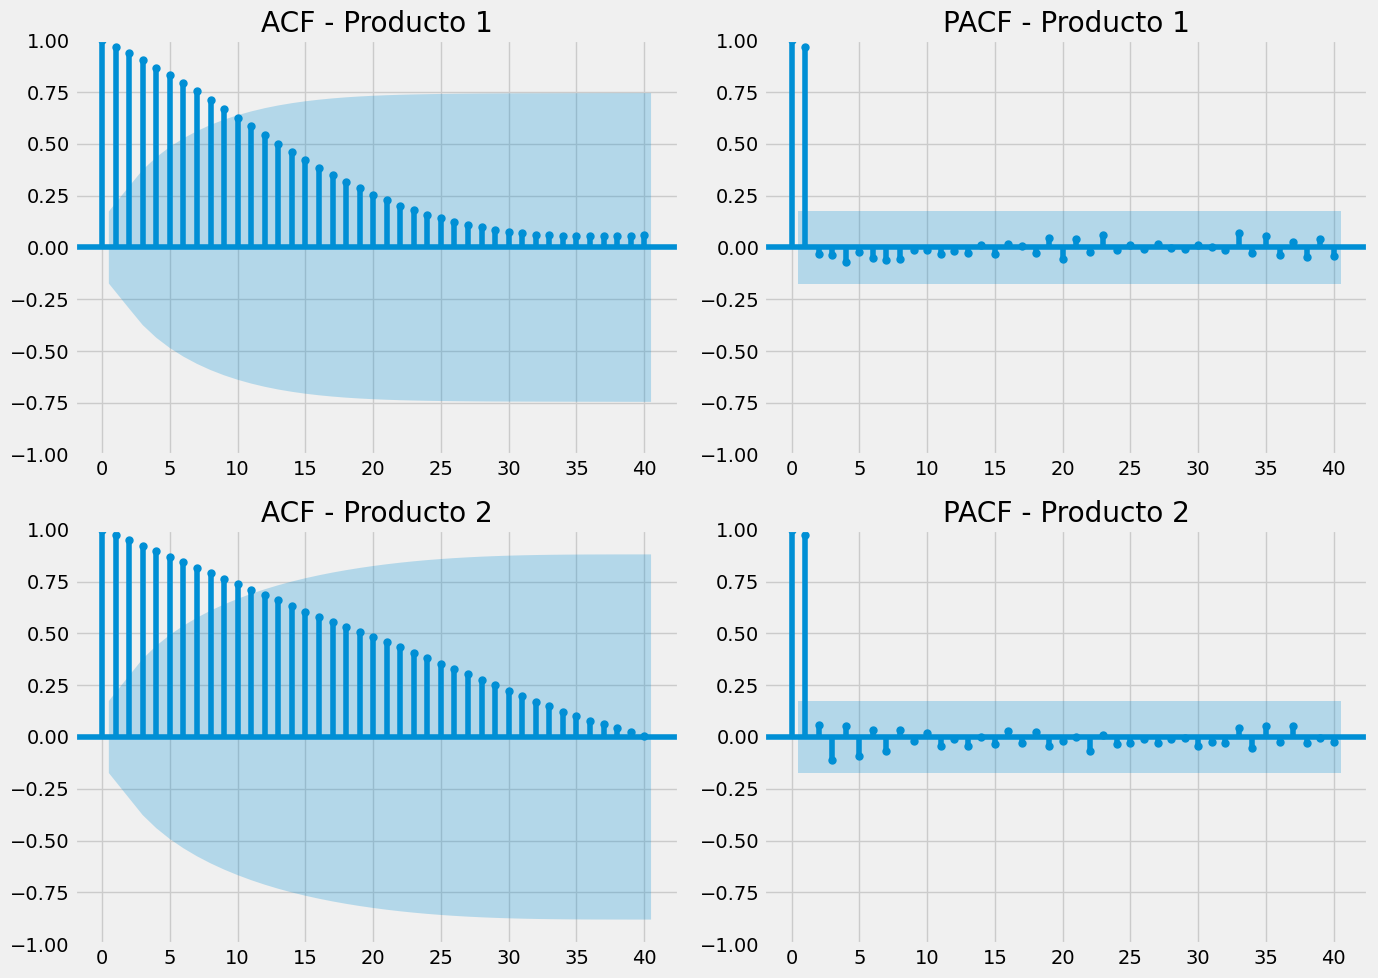

In [190]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Producto 1
plot_acf(data['producto1'], lags=40, ax=axes[0,0])
axes[0,0].set_title("ACF - Producto 1")

plot_pacf(data['producto1'], lags=40, ax=axes[0,1])
axes[0,1].set_title("PACF - Producto 1")

# Producto 2
plot_acf(data['producto2'], lags=40, ax=axes[1,0])
axes[1,0].set_title("ACF - Producto 2")

plot_pacf(data['producto2'], lags=40, ax=axes[1,1])
axes[1,1].set_title("PACF - Producto 2")

plt.tight_layout()
plt.show()


In [191]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
import warnings

warnings.filterwarnings("ignore")   # <--- evita spameo de ARIMA

# Asegurar frecuencia mensual
data.index = pd.to_datetime(data.index)
data = data.asfreq("MS")

# ---------- Función Rolling Window para ARIMA ----------
def rolling_window_evaluation_arima(
    data,
    target_column,
    initial_train_size,
    num_iterations,
    forecast_horizon=1,
    order=(1, 1, 1)
):
    test_errors = []
    forecasts = []

    for i in range(num_iterations):

        train_window = data.iloc[i:i + initial_train_size]
        test_window = data.iloc[i + initial_train_size:i + initial_train_size + forecast_horizon]

        y_train = train_window[target_column]
        y_test = test_window[target_column]

        try:
            model = ARIMA(y_train, order=order)
            model_fit = model.fit()

            test_predictions = model_fit.forecast(forecast_horizon)
            forecasts.append(test_predictions.iloc[0])

            test_error = np.sqrt(np.mean((y_test.values - test_predictions.values)**2))
            test_errors.append(test_error)

        except:
            continue

    average_rmse = np.mean(test_errors)
    return average_rmse, forecasts


# ---------- Configuración ----------
iterations = 12
train_size = data.shape[0] - iterations
horizon = 1

lista_ordenes_probar = [(p, d, q) for p in range(1,4) for d in range(1,4) for q in range(1,4)]

productos = {
    "producto1": data[["producto1"]].copy(),
    "producto2": data[["producto2"]].copy()
}

resultados_arima = {}
rmse_results_p1 = {}
rmse_results_p2 = {}

for target, df_prod in productos.items():
    print(f"\nEvaluando ARIMA para {target}...\n")
    mejor_rmse = None
    mejor_order = None
    mejor_forecasts = None

    for order in lista_ordenes_probar:
        avg_rmse, forecasts = rolling_window_evaluation_arima(
            data=df_prod,
            target_column=target,
            initial_train_size=train_size,
            num_iterations=iterations,
            forecast_horizon=horizon,
            order=order
        )

        print(f"ARIMA{order} - RMSE: {avg_rmse:.4f}")

        if target == "producto1":
            rmse_results_p1[str(order)] = avg_rmse
        else:
            rmse_results_p2[str(order)] = avg_rmse

        if (mejor_rmse is None) or (avg_rmse < mejor_rmse):
            mejor_rmse = avg_rmse
            mejor_order = order
            mejor_forecasts = forecasts

    resultados_arima[target] = {
        "best_order": mejor_order,
        "best_rmse": mejor_rmse,
        "forecasts": mejor_forecasts
    }

for target in resultados_arima:
    print(f"\n{target}: Mejor ARIMA{resultados_arima[target]['best_order']} con RMSE={resultados_arima[target]['best_rmse']:.4f}")



Evaluando ARIMA para producto1...

ARIMA(1, 1, 1) - RMSE: 6.4793
ARIMA(1, 1, 2) - RMSE: 7.5152
ARIMA(1, 1, 3) - RMSE: 6.4149
ARIMA(1, 2, 1) - RMSE: 5.5983
ARIMA(1, 2, 2) - RMSE: 5.9701
ARIMA(1, 2, 3) - RMSE: 5.6124
ARIMA(1, 3, 1) - RMSE: 6.3986
ARIMA(1, 3, 2) - RMSE: 5.6756
ARIMA(1, 3, 3) - RMSE: 6.0399
ARIMA(2, 1, 1) - RMSE: 4.7940
ARIMA(2, 1, 2) - RMSE: 5.3950
ARIMA(2, 1, 3) - RMSE: 5.5779
ARIMA(2, 2, 1) - RMSE: 5.6543
ARIMA(2, 2, 2) - RMSE: 5.9370
ARIMA(2, 2, 3) - RMSE: 5.9965
ARIMA(2, 3, 1) - RMSE: 5.6626
ARIMA(2, 3, 2) - RMSE: 5.7100
ARIMA(2, 3, 3) - RMSE: 5.6794
ARIMA(3, 1, 1) - RMSE: 4.8135
ARIMA(3, 1, 2) - RMSE: 4.7666
ARIMA(3, 1, 3) - RMSE: 5.3569
ARIMA(3, 2, 1) - RMSE: 5.6510
ARIMA(3, 2, 2) - RMSE: 6.5073
ARIMA(3, 2, 3) - RMSE: 5.8452
ARIMA(3, 3, 1) - RMSE: 5.7015
ARIMA(3, 3, 2) - RMSE: 5.7805
ARIMA(3, 3, 3) - RMSE: 5.9408

Evaluando ARIMA para producto2...

ARIMA(1, 1, 1) - RMSE: 10.8873
ARIMA(1, 1, 2) - RMSE: 8.7418
ARIMA(1, 1, 3) - RMSE: 8.6818
ARIMA(1, 2, 1) - RMSE: 8.13

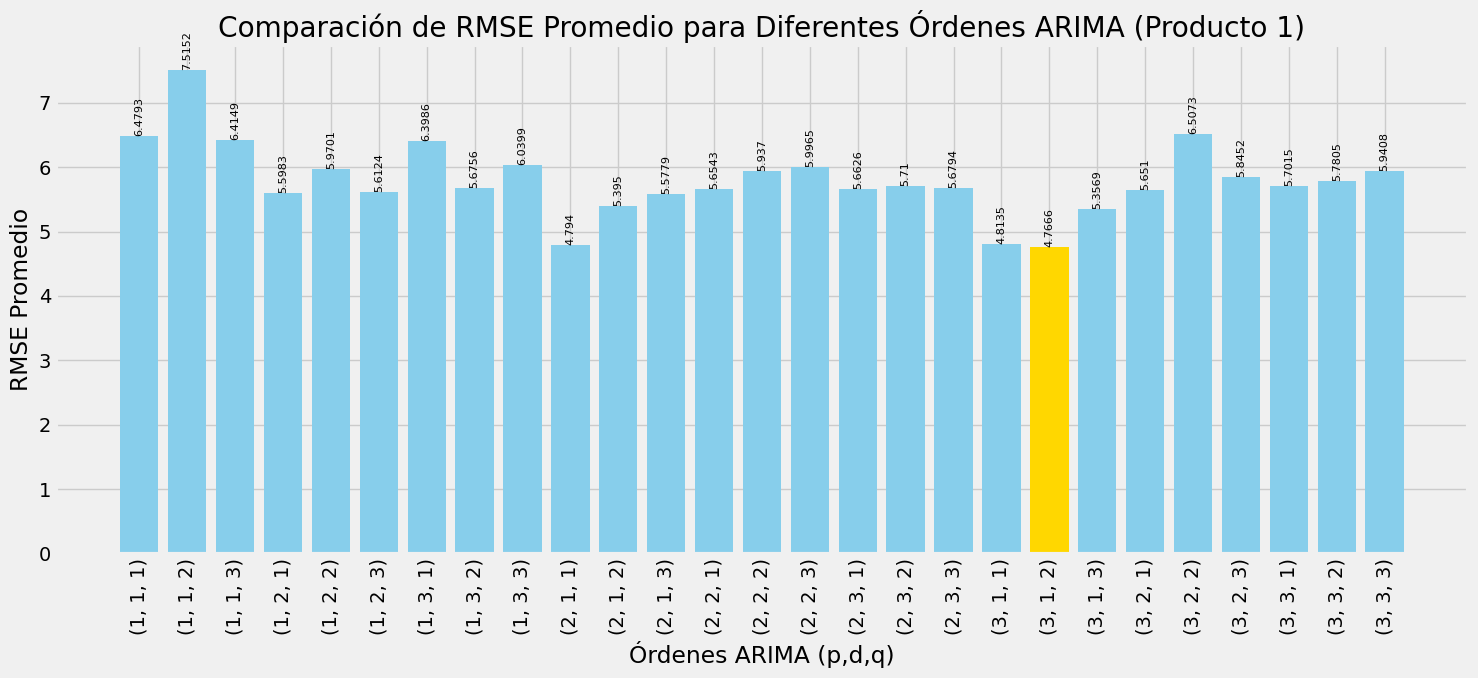

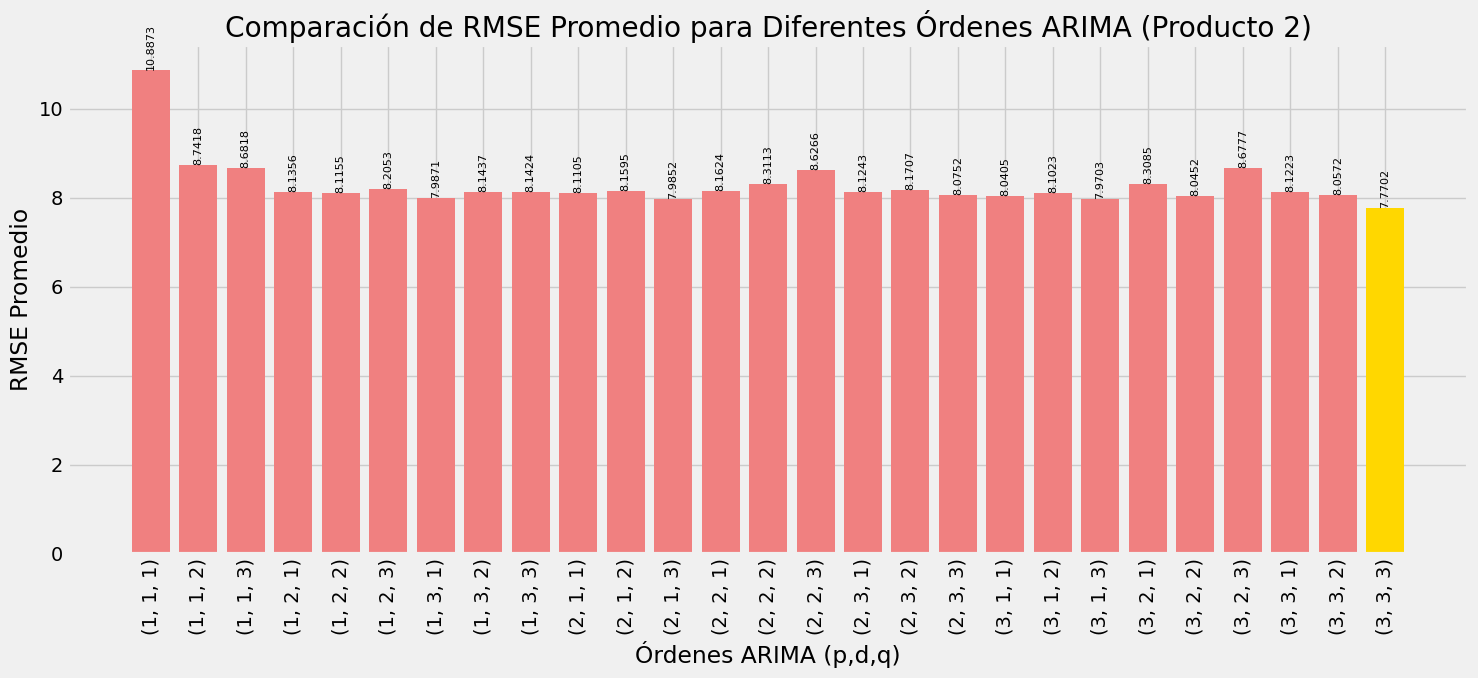

In [192]:
import matplotlib.pyplot as plt

# Para Producto 1
ordenes_p1 = [str(order) for order in rmse_results_p1.keys()]
ARIMA_rmse_values_p1 = list(rmse_results_p1.values())

# Identificar el mejor RMSE para Producto 1
min_rmse_p1 = min(ARIMA_rmse_values_p1)
colors_p1 = ['gold' if rmse == min_rmse_p1 else 'skyblue' for rmse in ARIMA_rmse_values_p1]

plt.figure(figsize=(15, 7))
bars_p1 = plt.bar(ordenes_p1, ARIMA_rmse_values_p1, color=colors_p1)

# Agregar etiquetas a cada barra con el valor del RMSE de forma vertical
for bar in bars_p1:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval,
        round(yval, 4),
        ha='center',
        va='bottom',
        fontsize=8,
        rotation=90  # Rotación vertical
    )

plt.xticks(rotation=90)
plt.xlabel('Órdenes ARIMA (p,d,q)')
plt.ylabel('RMSE Promedio')
plt.title('Comparación de RMSE Promedio para Diferentes Órdenes ARIMA (Producto 1)')
plt.tight_layout()
plt.show()

# Para Producto 2
ordenes_p2 = [str(order) for order in rmse_results_p2.keys()]
ARIMA_rmse_values_p2 = list(rmse_results_p2.values())

# Identificar el mejor RMSE para Producto 2
min_rmse_p2 = min(ARIMA_rmse_values_p2)
colors_p2 = ['gold' if rmse == min_rmse_p2 else 'lightcoral' for rmse in ARIMA_rmse_values_p2]

plt.figure(figsize=(15, 7))
bars_p2 = plt.bar(ordenes_p2, ARIMA_rmse_values_p2, color=colors_p2)

# Agregar etiquetas a cada barra con el valor del RMSE de forma vertical
for bar in bars_p2:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval,
        round(yval, 4),
        ha='center',
        va='bottom',
        fontsize=8,
        rotation=90  # Rotación vertical
    )

plt.xticks(rotation=90)
plt.xlabel('Órdenes ARIMA (p,d,q)')
plt.ylabel('RMSE Promedio')
plt.title('Comparación de RMSE Promedio para Diferentes Órdenes ARIMA (Producto 2)')
plt.tight_layout()
plt.show()

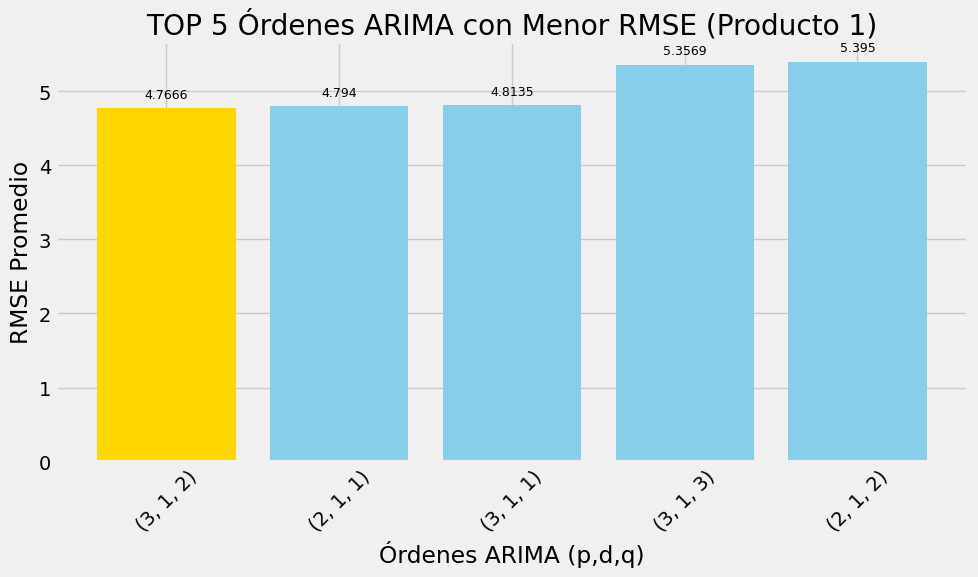

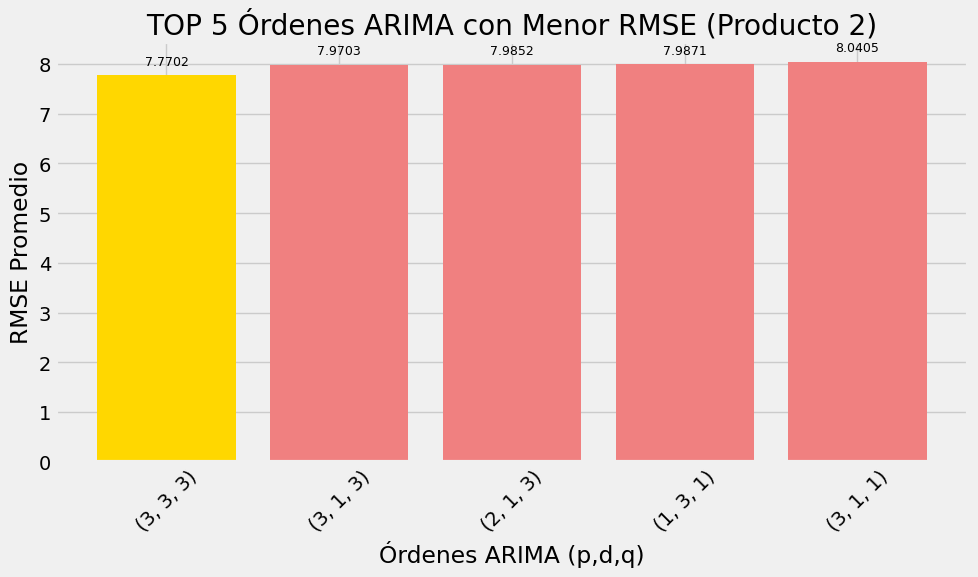

In [193]:
import matplotlib.pyplot as plt

# =========================
#       PRODUCTO 1
# =========================

# Top 5 menores RMSE
sorted_p1 = sorted(rmse_results_p1.items(), key=lambda x: x[1])[:5]

ordenes_p1 = [str(order) for order, rmse in sorted_p1]
ARIMA_rmse_values_p1 = [rmse for order, rmse in sorted_p1]

min_rmse_p1 = min(ARIMA_rmse_values_p1)
colors_p1 = ['gold' if rmse == min_rmse_p1 else 'skyblue' for rmse in ARIMA_rmse_values_p1]

plt.figure(figsize=(10, 6))
bars_p1 = plt.bar(ordenes_p1, ARIMA_rmse_values_p1, color=colors_p1)

# Etiquetas horizontales
for bar in bars_p1:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + (yval * 0.02),  # pequeño desplazamiento hacia arriba
        round(yval, 4),
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.xticks(rotation=45)
plt.xlabel('Órdenes ARIMA (p,d,q)')
plt.ylabel('RMSE Promedio')
plt.title('TOP 5 Órdenes ARIMA con Menor RMSE (Producto 1)')
plt.tight_layout()
plt.show()


# =========================
#       PRODUCTO 2
# =========================

sorted_p2 = sorted(rmse_results_p2.items(), key=lambda x: x[1])[:5]

ordenes_p2 = [str(order) for order, rmse in sorted_p2]
ARIMA_rmse_values_p2 = [rmse for order, rmse in sorted_p2]

min_rmse_p2 = min(ARIMA_rmse_values_p2)
colors_p2 = ['gold' if rmse == min_rmse_p2 else 'lightcoral' for rmse in ARIMA_rmse_values_p2]

plt.figure(figsize=(10, 6))
bars_p2 = plt.bar(ordenes_p2, ARIMA_rmse_values_p2, color=colors_p2)

# Etiquetas horizontales
for bar in bars_p2:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + (yval * 0.02),
        round(yval, 4),
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.xticks(rotation=45)
plt.xlabel('Órdenes ARIMA (p,d,q)')
plt.ylabel('RMSE Promedio')
plt.title('TOP 5 Órdenes ARIMA con Menor RMSE (Producto 2)')
plt.tight_layout()
plt.show()


### Comparación de RMSE para Producto 1

In [194]:
import pandas as pd

# Recopilar los RMSE de los modelos para Producto 1
# Promedio Móvil
rmse_ma_producto1 = np.mean(ma_test_errors_1)

# ETS Optimizado (Bayesian Optimization)
rmse_ets_producto1 = -optimizer_p1.max['target']

# Polinomial
rmse_polynomial_producto1 = resultados_polynomial['producto1']['best_rmse']

# ARIMA
rmse_arima_producto1 = resultados_arima['producto1']['best_rmse']

# Crear DataFrame para la comparación
comparison_data_p1 = {
    'Modelo': [
        'Promedio Móvil',
        'ETS Optimizado (Bayes)',
        'Regresión Polinomial + Estacionalidad',
        'ARIMA'
    ],
    'RMSE': [
        rmse_ma_producto1,
        rmse_ets_producto1,
        rmse_polynomial_producto1,
        rmse_arima_producto1
    ]
}

df_comparison_p1 = pd.DataFrame(comparison_data_p1)
df_comparison_p1 = df_comparison_p1.sort_values(by='RMSE', ascending=True)

print("Comparación de RMSE para Producto 1:")
print(df_comparison_p1)


Comparación de RMSE para Producto 1:
                                  Modelo      RMSE
3                                  ARIMA  4.766611
1                 ETS Optimizado (Bayes)  5.426490
2  Regresión Polinomial + Estacionalidad  5.468520
0                         Promedio Móvil  7.925841


### Comparación de RMSE para Producto 2

In [195]:
# Recopilar los RMSE de los modelos para Producto 2
# Promedio Móvil
rmse_ma_producto2 = np.mean(ma_test_errors_2)

# ETS Optimizado (Bayesian Optimization)
rmse_ets_producto2 = -optimizer_p2.max['target']

# Polinomial
rmse_polynomial_producto2 = resultados_polynomial['producto2']['best_rmse']

# ARIMA
rmse_arima_producto2 = resultados_arima['producto2']['best_rmse']

# Crear DataFrame para la comparación
comparison_data_p2 = {
    'Modelo': [
        'Promedio Móvil',
        'ETS Optimizado (Bayes)',
        'Regresión Polinomial + Estacionalidad',
        'ARIMA'
    ],
    'RMSE': [
        rmse_ma_producto2,
        rmse_ets_producto2,
        rmse_polynomial_producto2,
        rmse_arima_producto2
    ]
}

df_comparison_p2 = pd.DataFrame(comparison_data_p2)
df_comparison_p2 = df_comparison_p2.sort_values(by='RMSE', ascending=True)

print("Comparación de RMSE para Producto 2:")
print(df_comparison_p2)


Comparación de RMSE para Producto 2:
                                  Modelo       RMSE
1                 ETS Optimizado (Bayes)   6.927364
2  Regresión Polinomial + Estacionalidad   7.227086
3                                  ARIMA   7.770159
0                         Promedio Móvil  14.409853


##7.5. Modelos VAR con ventana Móvil

In [196]:
def rolling_window_var(original_data_full, initial_train_size, num_iterations, forecast_horizon=1, verbose=False):

    rmse_list_p1 = []
    rmse_list_p2 = []
    forecasts_list = []

    # Aseguramos que original_data_full sea un DataFrame y tenga las columnas esperadas
    if not isinstance(original_data_full, pd.DataFrame) or not all(col in original_data_full.columns for col in ['producto1', 'producto2']):
        raise ValueError("original_data_full debe ser un DataFrame con columnas 'producto1' y 'producto2'")

    for i in range(num_iterations):
        # 1. Obtener ventanas de entrenamiento y prueba de los datos ORIGINALES
        train_original = original_data_full.iloc[i : i + initial_train_size]
        test_original = original_data_full.iloc[i + initial_train_size : i + initial_train_size + forecast_horizon]

        # Asegurarse de que no haya ventanas de prueba vacías
        if len(test_original) == 0:
            if verbose:
                print(f"Saltando iteración {i+1} debido a ventana de prueba vacía.")
            continue

        # 2. Diferenciar los datos de entrenamiento para el ajuste del modelo VAR
        # Asumiendo d=1 para ambas series basado en el diagnóstico previo.
        # La diferenciación se hace en cada ventana de entrenamiento.
        train_differenced = train_original.diff().dropna()

        # Si después de diferenciar, el conjunto de entrenamiento es demasiado corto, saltar
        if len(train_differenced) < 2: # VAR necesita al menos 2 observaciones para ajustar
            if verbose:
                print(f"Saltando iteración {i+1} debido a datos diferenciados insuficientes.")
            continue

        # 3. Ajustar VAR en los datos diferenciados
        model = VAR(train_differenced)
        try:
            # Seleccionar el mejor lag hasta 4 para datos diferenciados, usando AIC
            # Un maxlags muy alto en datos diferenciados podría causar inestabilidad si la serie es corta
            results = model.fit(maxlags=4, ic="aic") # maxlags en datos diferenciados
        except Exception as e:
            if verbose:
                print(f"Saltando iteración {i+1} debido a error de ajuste VAR: {e}")
            continue

        lag = results.k_ar # Lag óptimo seleccionado por AIC

        # 4. Pronosticar la serie DIFERENCIADA
        # Se usa el último 'lag' de las observaciones diferenciadas para el pronóstico
        forecast_differenced = results.forecast(train_differenced.values[-lag:], steps=forecast_horizon)

        # 5. Desdiferenciar los pronósticos a la escala ORIGINAL
        # Para d=1, forecast_original[t] = forecast_differenced[t] + actual_original[t-1]
        last_original_values = train_original.iloc[-1].values # Últimos valores del TRAIN ORIGINAL

        forecast_original = np.zeros_like(forecast_differenced)
        for h in range(forecast_horizon):
            # Desdiferenciar Producto 1
            forecast_original[h, 0] = forecast_differenced[h, 0] + last_original_values[0]
            # Desdiferenciar Producto 2
            forecast_original[h, 1] = forecast_differenced[h, 1] + last_original_values[1]
            # Actualizar last_original_values para pronósticos multi-paso (si forecast_horizon > 1)
            last_original_values = forecast_original[h, :]

        # 6. Calcular RMSE en la escala ORIGINAL
        real_values = test_original.values

        if len(real_values) == 0 or len(forecast_original) == 0: # Doble chequeo
            if verbose:
                print(f"Saltando iteración {i+1} debido a ventana de prueba/pronóstico vacía.")
            continue

        rmse_p1 = np.sqrt(mean_squared_error(real_values[:, 0], forecast_original[:, 0]))
        rmse_p2 = np.sqrt(mean_squared_error(real_values[:, 1], forecast_original[:, 1]))

        rmse_list_p1.append(rmse_p1)
        rmse_list_p2.append(rmse_p2)
        forecasts_list.append(forecast_original[0]) # Almacenar el pronóstico del primer paso para visualización

        if verbose:
            print(f"Iteración {i+1}/{num_iterations}  -  RMSE P1 = {rmse_p1:.4f}, RMSE P2 = {rmse_p2:.4f}")

    # Asegurarse de que las listas no estén vacías antes de calcular la media
    if not rmse_list_p1 or not rmse_list_p2:
        if verbose:
            print("No se pudieron calcular RMSEs para el modelo VAR en ninguna iteración.")
        return np.inf, np.inf, []

    return np.mean(rmse_list_p1), np.mean(rmse_list_p2), forecasts_list


### VAR para producto 1 y 2

In [197]:
# Re-inicializar original_data para asegurar que siempre esté definida
# Esto es crucial para la evaluación del modelo VAR que espera los datos sin diferenciar.
original_data = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Maestría en Ciencia de Datos/Semestre 1/Fundamentos de Analítica 1/Sesión 11/Examen.csv")
original_data['Date'] = pd.date_range(start='2014-06-01', periods=len(original_data), freq='MS')
original_data.set_index('Date', inplace=True)
if 'Unnamed: 0' in original_data.columns:
    original_data.drop(columns=['Unnamed: 0'], inplace=True)

iterations = 12
train_size = original_data.shape[0] - iterations # 'original_data' here to be consistent

# La función rolling_window_var ahora espera los datos ORIGINALES, no los diferenciados
rmse_var_p1, rmse_var_p2, forecasts_var = rolling_window_var(
    original_data_full=original_data[["producto1","producto2"]], # Usar los datos originales aquí
    initial_train_size=train_size,
    num_iterations=iterations,
    forecast_horizon=1,
    verbose=True
)

print("\nRMSE promedio VAR (desdiferenciado) para Producto 1:", rmse_var_p1)
print("RMSE promedio VAR (desdiferenciado) para Producto 2:", rmse_var_p2)


Iteración 1/12  -  RMSE P1 = 1.9024, RMSE P2 = 2.5725
Iteración 2/12  -  RMSE P1 = 3.0681, RMSE P2 = 8.0226
Iteración 3/12  -  RMSE P1 = 14.3789, RMSE P2 = 0.7838
Iteración 4/12  -  RMSE P1 = 0.5819, RMSE P2 = 11.4209
Iteración 5/12  -  RMSE P1 = 2.5235, RMSE P2 = 17.0698
Iteración 6/12  -  RMSE P1 = 7.0561, RMSE P2 = 0.4457
Iteración 7/12  -  RMSE P1 = 4.9316, RMSE P2 = 12.0752
Iteración 8/12  -  RMSE P1 = 5.0829, RMSE P2 = 0.3446
Iteración 9/12  -  RMSE P1 = 11.8370, RMSE P2 = 3.1860
Iteración 10/12  -  RMSE P1 = 1.3947, RMSE P2 = 13.4348
Iteración 11/12  -  RMSE P1 = 2.1868, RMSE P2 = 12.4594
Iteración 12/12  -  RMSE P1 = 9.1561, RMSE P2 = 4.9190

RMSE promedio VAR (desdiferenciado) para Producto 1: 5.341656938553264
RMSE promedio VAR (desdiferenciado) para Producto 2: 7.227854205786305


###Producto 1

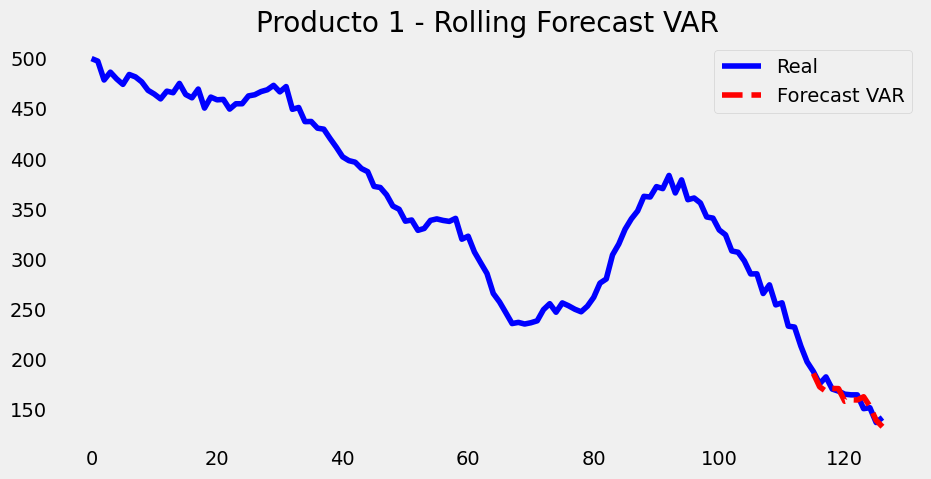

In [198]:
real = data["producto1"].values

plt.figure(figsize=(10,5))
plt.plot(real, label="Real", color='blue')

# anexar pronósticos al final
valores_forecast = [f[0] for f in forecasts_var]
plt.plot(range(train_size, train_size+iterations), valores_forecast,
         label="Forecast VAR", color='red', linestyle='--')

plt.title("Producto 1 - Rolling Forecast VAR")
plt.legend()
plt.grid()
plt.show()


###Producto 2

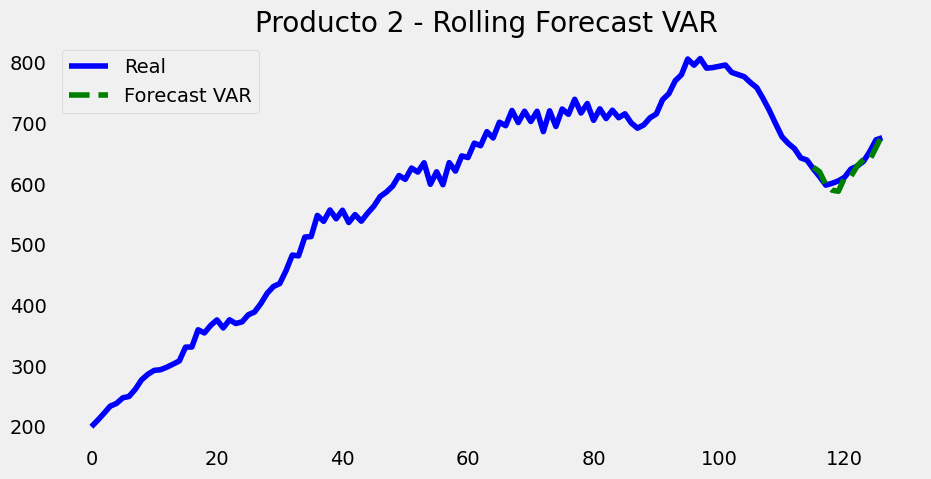

In [199]:
real = data["producto2"].values

plt.figure(figsize=(10,5))
plt.plot(real, label="Real", color='blue')

valores_forecast = [f[1] for f in forecasts_var]
plt.plot(range(train_size, train_size+iterations), valores_forecast,
         label="Forecast VAR", color='green', linestyle='--')

plt.title("Producto 2 - Rolling Forecast VAR")
plt.legend()
plt.grid()
plt.show()


In [200]:
actual_p1 = data['producto1'].iloc[train_size : train_size + iterations]
forecasts_p1_var = [f[0] for f in forecasts_var]
rmse_var_p1 = np.sqrt(mean_squared_error(actual_p1, forecasts_p1_var))

actual_p2 = data['producto2'].iloc[train_size : train_size + iterations]
forecasts_p2_var = [f[1] for f in forecasts_var]
rmse_var_p2 = np.sqrt(mean_squared_error(actual_p2, forecasts_p2_var))

# Obtener los grados polinomiales
best_degree_p1_poly = resultados_polynomial['producto1']['best_degree']
best_degree_p2_poly = resultados_polynomial['producto2']['best_degree']

# Una alternativa sería:
modelo_p1_poly = f"Polinómico (grado {best_degree_p1_poly})"
modelo_p2_poly = f"Polinómico (grado {best_degree_p2_poly})"

tabla_final_rmse_p1 = pd.DataFrame({
    "Modelo": ["Promedio Móvil", "ARIMA", "ETS Optimizado", modelo_p1_poly, "VAR"],
    "RMSE": [
        rmse_ma_producto1,
        rmse_arima_producto1,
        rmse_ets_producto1,
        rmse_polynomial_producto1,
        rmse_var_p1,

    ]
}).sort_values(by="RMSE")

tabla_final_rmse_p2 = pd.DataFrame({
    "Modelo": ["Promedio Móvil", "ARIMA", "ETS Optimizado", modelo_p2_poly, "VAR"],
    "RMSE": [
        rmse_ma_producto2,
        rmse_arima_producto2,
        rmse_ets_producto2,
        rmse_polynomial_producto2,
        rmse_var_p2,

    ]
}).sort_values(by="RMSE")

print("\n================ TABLA FINAL DE RMSE PARA PRODUCTO 1 ================\n")
print(tabla_final_rmse_p1)
print("\n================ TABLA FINAL DE RMSE PARA PRODUCTO 2 ================\n")
print(tabla_final_rmse_p2)



================ TABLA FINAL DE RMSE PARA PRODUCTO 1 ================

                 Modelo      RMSE
1                 ARIMA  4.766611
2        ETS Optimizado  5.426490
3  Polinómico (grado 6)  5.468520
4                   VAR  6.813667
0        Promedio Móvil  7.925841

================ TABLA FINAL DE RMSE PARA PRODUCTO 2 ================

                 Modelo       RMSE
2        ETS Optimizado   6.927364
3  Polinómico (grado 3)   7.227086
1                 ARIMA   7.770159
4                   VAR   9.172480
0        Promedio Móvil  14.409853


##7.6. PROPHET

### Preparar datos para Prophet

In [201]:
# ==========================================================
# PARCHE DEFINITIVO PARA DESHABILITAR CMDSTAN EN PROPHET
# ==========================================================


class NoStanBackend:
    def __init__(self, *args, **kwargs):
        pass
    def fit(self, *args, **kwargs):
        # Devolvemos algo vacío pero que no produce error
        return {}

# Reemplazar el backend por defecto (CMDSTAN)
pm_models.StanBackendEnum.CMDSTAN = NoStanBackend


# Preparar los DataFrames para Prophet (ds, y)


df_p1 = data_producto1.reset_index().rename(columns={'index': 'ds', 'producto1': 'y'})
df_p2 = data_producto2.reset_index().rename(columns={'index': 'ds', 'producto2': 'y'})

# Asegurar que 'ds' sea datetime para Prophet
df_p1['ds'] = pd.to_datetime(df_p1['ds'])
df_p2['ds'] = pd.to_datetime(df_p2['ds'])


# ------------------------------------------------------------------------------------------
# 1) CREAR EVENTO DE NAVIDAD (para serie mensual)
# ------------------------------------------------------------------------------------------
def add_christmas_event(df):
    df = df.copy()
    df["Christmas"] = df["ds"].dt.month.eq(12).astype(int)

    holidays = pd.DataFrame({
        'holiday': 'Christmas',
        'ds': df.loc[df["Christmas"] == 1, "ds"],
        'lower_window': 0,
        'upper_window': 0
    })
    return df, holidays


# ------------------------------------------------------------------------------------------
# 2) ROLLING WINDOW EVALUATION (mensual)
# ------------------------------------------------------------------------------------------
def rolling_window_prophet(df, holidays, params, initial_train_size, num_iterations, horizon=1):
    df = df.sort_values("ds").reset_index(drop=True)
    n = len(df)
    rmses = []

    # Iterar num_iterations veces para el rolling window
    for i in range(num_iterations):
        train = df.iloc[i : i + initial_train_size]
        test  = df.iloc[i + initial_train_size : i + initial_train_size + horizon]

        # Si la ventana de prueba es vacía, saltar
        if len(test) == 0:
            # Esto puede pasar si initial_train_size + i + horizon excede n
            continue

        model = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=False,
            daily_seasonality=False,
            holidays=holidays,
            changepoint_prior_scale=params["changepoint_prior_scale"],
            seasonality_prior_scale=params["seasonality_prior_scale"],
            holidays_prior_scale=params["holidays_prior_scale"],
            n_changepoints=params["n_changepoints"],
            seasonality_mode=params["seasonality_mode"]
        )

        # Configurar logging para evitar la salida de Prophet en cada iteración
        import logging
        logger = logging.getLogger('cmdstanpy')
        logger.setLevel(logging.WARNING)

        model.fit(train) # Eliminado verbose=False

        future = test[["ds"]]
        forecast = model.predict(future)

        rmse = np.sqrt(mean_squared_error(test["y"], forecast["yhat"]))
        rmses.append(rmse)

    # Manejar caso de rmses vacio si no hubo iteraciones validas
    if len(rmses) == 0:
        return np.inf # Retornar infinito si no hay RMSEs para indicar un fallo

    return np.mean(rmses)


# ------------------------------------------------------------------------------------------
# 3) FUNCIÓN OBJETIVO PARA OPTUNA
# ------------------------------------------------------------------------------------------
def prophet_objective(trial, df, holidays, initial_train_size, num_iterations):
    params = {
        "changepoint_prior_scale": trial.suggest_float("changepoint_prior_scale", 0.001, 0.5, log=True),
        "seasonality_prior_scale": trial.suggest_float("seasonality_prior_scale", 0.1, 10, log=True),
        "holidays_prior_scale": trial.suggest_float("holidays_prior_scale", 0.1, 10, log=True),
        "n_changepoints": trial.suggest_int("n_changepoints", 5, 30),
        "seasonality_mode": trial.suggest_categorical("seasonality_mode", ["additive", "multiplicative"])
    }

    rmse = rolling_window_prophet(df, holidays, params, initial_train_size, num_iterations)
    return rmse


# ------------------------------------------------------------------------------------------
# 4) PROCESO COMPLETO PARA UN PRODUCTO
# ------------------------------------------------------------------------------------------
def run_prophet_for_product(df, product_name):
    # Usar las variables globales train_size e iterations definidas previamente
    global train_size, iterations

    print(f"\n==============================")
    print(f"      PROPHET PARA {product_name}")
    print(f"==============================")

    # Crear evento Navidad
    df_holidays, holidays = add_christmas_event(df)

    # OPTIMIZACIÓN BAYESIANA
    study = optuna.create_study(direction="minimize")
    study.optimize(lambda t: prophet_objective(t, df_holidays, holidays, train_size, iterations), n_trials=25)

    best_params = study.best_params
    best_rmse   = study.best_value

    print("\n> Mejores parámetros encontrados:")
    print(best_params)
    print(f"> RMSE promedio Rolling Window: {best_rmse:.4f}")

    # ENTRENAR MODELO FINAL CON TODOS LOS DATOS
    model_final = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        holidays=holidays,
        changepoint_prior_scale=best_params["changepoint_prior_scale"],
        seasonality_prior_scale=best_params["seasonality_prior_scale"],
        holidays_prior_scale=best_params["holidays_prior_scale"],
        n_changepoints=best_params["n_changepoints"],
        seasonality_mode=best_params["seasonality_mode"]
    )

    model_final.fit(df_holidays) # Eliminado verbose=False

    # Pronóstico 1 mes hacia adelante (como ARIMA/ETS)
    future = model_final.make_future_dataframe(periods=1, freq="MS")
    future["Christmas"] = future["ds"].dt.month.eq(12).astype(int)

    forecast = model_final.predict(future)

    forecast_next = forecast.tail(1)[["ds", "yhat", "yhat_lower", "yhat_upper"]]

    print("\n> Próximo pronóstico:")
    print(forecast_next)

    return {
        "product": product_name,
        "best_params": best_params,
        "rmse": best_rmse,
        "forecast": forecast_next
    }


# ------------------------------------------------------------------------------------------
# 5) EJECUCIÓN PARA P1 Y P2
# ------------------------------------------------------------------------------------------
result_p1 = run_prophet_for_product(df_p1, "PRODUCTO 1")
result_p2 = run_prophet_for_product(df_p2, "PRODUCTO 2")

# ------------------------------------------------------------------------------------------
# 6) TABLA FINAL PARA INFORME
# ------------------------------------------------------------------------------------------
tabla_final = pd.DataFrame({
    "Producto": ["PRODUCTO 1", "PRODUCTO 2"],
    "RMSE Rolling": [result_p1["rmse"], result_p2["rmse"]],
    "Pronóstico": [
        float(result_p1["forecast"]["yhat"]),
        float(result_p2["forecast"]["yhat"])
    ],
    "IC Lower": [
        float(result_p1["forecast"]["yhat_lower"]),
        float(result_p2["forecast"]["yhat_lower"])
    ],
    "IC Upper": [
        float(result_p1["forecast"]["yhat_upper"]),
        float(result_p2["forecast"]["yhat_upper"])
    ]
})

print("\n===================================")
print("      TABLA FINAL PARA INFORME")
print("===================================")
print(tabla_final)


[I 2025-12-06 20:34:45,073] A new study created in memory with name: no-name-c029713f-2528-4637-a9d7-580a001ed010
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted



      PROPHET PARA PRODUCTO 1


ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
[I 2025-12-06 20:34:49,214] Trial 0 finished with value: 56.07208487963465 and parameters: {'changepoint_prior_scale': 0.0018224643395808966, 'seasonality_prior_scale': 0.49186286064701357, 'holidays_prior_scale': 9.707314345562452, 'n_changepoints': 19, 'seasonality_mode':


> Mejores parámetros encontrados:
{'changepoint_prior_scale': 0.1131121730177472, 'seasonality_prior_scale': 0.7589134465207443, 'holidays_prior_scale': 0.1755483312222665, 'n_changepoints': 28, 'seasonality_mode': 'multiplicative'}
> RMSE promedio Rolling Window: 13.7470

> Próximo pronóstico:
            ds        yhat  yhat_lower  yhat_upper
127 2025-01-01  113.946032  101.072753  126.819324

      PROPHET PARA PRODUCTO 2


ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
[I 2025-12-06 20:35:36,365] Trial 0 finished with value: 70.11851845910984 and parameters: {'changepoint_prior_scale': 0.02857207507911468, 'seasonality_prior_scale': 8.978472116114512, 'holidays_prior_scale': 0.4654917510143122, 'n_changepoints': 5, 'seasonality_mode': 'multiplicative'}. Best is trial 0 with value: 70.11851845910984.
[I 2025-12-06 20:35:38,091] Trial 1 finished with value: 123.50204107311664 and parameters: {'changepoint_prior_scale': 0.018198820064946417, 'seasonality_prior_scale': 3.5866532512443654, 'holidays_prior_scale': 2.5960505839263135, 'n_changepoints': 11, 'seasonality


> Mejores parámetros encontrados:
{'changepoint_prior_scale': 0.37910436857806945, 'seasonality_prior_scale': 0.1006466171893286, 'holidays_prior_scale': 9.556445068053984, 'n_changepoints': 30, 'seasonality_mode': 'additive'}
> RMSE promedio Rolling Window: 61.3909

> Próximo pronóstico:
            ds        yhat  yhat_lower  yhat_upper
127 2025-01-01  578.512414  552.105909  606.228826

      TABLA FINAL PARA INFORME
     Producto  RMSE Rolling  Pronóstico    IC Lower    IC Upper
0  PRODUCTO 1     13.747001  113.946032  101.072753  126.819324
1  PRODUCTO 2     61.390853  578.512414  552.105909  606.228826


#8. Tabla de Resultados de Metrica

In [202]:
train_size_original_data = len(original_data) - iterations

# Obtener los valores reales del periodo de evaluación de la SERIE ORIGINAL
actual_p1_original = original_data['producto1'].iloc[
    train_size_original_data : train_size_original_data + iterations
]
actual_p2_original = original_data['producto2'].iloc[
    train_size_original_data : train_size_original_data + iterations
]

# Los forecasts_var ya vienen desdiferenciados gracias a la modificación en rolling_window_var
forecasts_p1_var = [f[0] for f in forecasts_var]
forecasts_p2_var = [f[1] for f in forecasts_var]

# Recalcular RMSEs del VAR con los valores reales originales y pronósticos desdiferenciados
rmse_var_p1 = np.sqrt(mean_squared_error(actual_p1_original, forecasts_p1_var))
rmse_var_p2 = np.sqrt(mean_squared_error(actual_p2_original, forecasts_p2_var))

# Obtener los grados polinomiales
best_degree_p1_poly = resultados_polynomial['producto1']['best_degree']
best_degree_p2_poly = resultados_polynomial['producto2']['best_degree']

# Obtener RMSE de Prophet
rmse_prophet_p1 = result_p1["rmse"]
rmse_prophet_p2 = result_p2["rmse"]

# Etiquetas descriptivas para el modelo polinomial
modelo_p1_poly = f"Polinómico (grado {best_degree_p1_poly})"
modelo_p2_poly = f"Polinómico (grado {best_degree_p2_poly})"

# Tabla final RMSE para producto 1
tabla_final_rmse_p1 = pd.DataFrame({
    "Modelo": [
        "Promedio Móvil",
        "ARIMA",
        "ETS Optimizado",
        modelo_p1_poly,
        "VAR",
        "Prophet"
    ],
    "RMSE": [
        rmse_ma_producto1,
        rmse_arima_producto1,
        rmse_ets_producto1,
        rmse_polynomial_producto1,
        rmse_var_p1,
        rmse_prophet_p1
    ]
}).sort_values(by="RMSE")

# Tabla final RMSE para producto 2
tabla_final_rmse_p2 = pd.DataFrame({
    "Modelo": [
        "Promedio Móvil",
        "ARIMA",
        "ETS Optimizado",
        modelo_p2_poly,
        "VAR",
        "Prophet"
    ],
    "RMSE": [
        rmse_ma_producto2,
        rmse_arima_producto2,
        rmse_ets_producto2,
        rmse_polynomial_producto2,
        rmse_var_p2,
        rmse_prophet_p2
    ]
}).sort_values(by="RMSE")

print("\n================ TABLA FINAL DE RMSE PARA PRODUCTO 1 ================\n")
print(tabla_final_rmse_p1)

print("\n================ TABLA FINAL DE RMSE PARA PRODUCTO 2 ================\n")
print(tabla_final_rmse_p2)



================ TABLA FINAL DE RMSE PARA PRODUCTO 1 ================

                 Modelo       RMSE
1                 ARIMA   4.766611
2        ETS Optimizado   5.426490
3  Polinómico (grado 6)   5.468520
4                   VAR   6.813667
0        Promedio Móvil   7.925841
5               Prophet  13.747001

================ TABLA FINAL DE RMSE PARA PRODUCTO 2 ================

                 Modelo       RMSE
2        ETS Optimizado   6.927364
3  Polinómico (grado 3)   7.227086
1                 ARIMA   7.770159
4                   VAR   9.172480
0        Promedio Móvil  14.409853
5               Prophet  61.390853


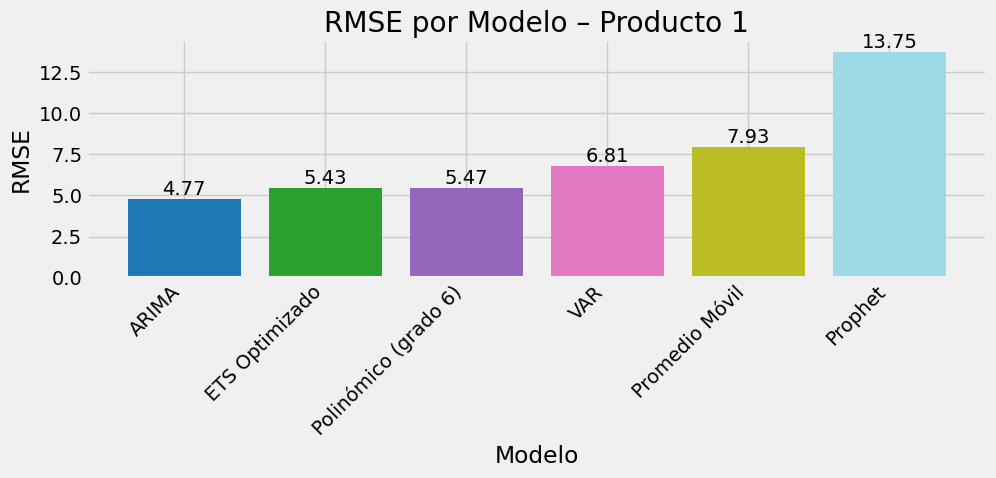

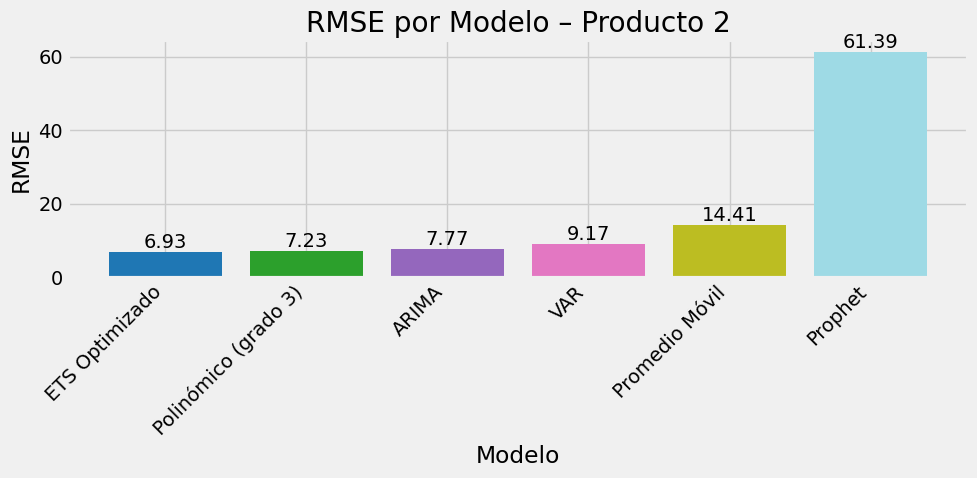

In [203]:
# =================== GRÁFICO DE BARRAS PARA PRODUCTO 1 ===================

plt.figure(figsize=(10, 5))

# Colores distintos para cada barra
colors_p1 = plt.cm.tab20(np.linspace(0, 1, len(tabla_final_rmse_p1)))

plt.bar(tabla_final_rmse_p1["Modelo"], tabla_final_rmse_p1["RMSE"], color=colors_p1)

plt.title("RMSE por Modelo – Producto 1")
plt.xlabel("Modelo")
plt.ylabel("RMSE")
plt.xticks(rotation=45, ha='right')

# Agregar valor encima de cada barra
for idx, value in enumerate(tabla_final_rmse_p1["RMSE"]):
    plt.text(idx, value, f"{value:.2f}", ha='center', va='bottom')

plt.tight_layout()
plt.show()


# =================== GRÁFICO DE BARRAS PARA PRODUCTO 2 ===================

plt.figure(figsize=(10, 5))

colors_p2 = plt.cm.tab20(np.linspace(0, 1, len(tabla_final_rmse_p2)))

plt.bar(tabla_final_rmse_p2["Modelo"], tabla_final_rmse_p2["RMSE"], color=colors_p2)

plt.title("RMSE por Modelo – Producto 2")
plt.xlabel("Modelo")
plt.ylabel("RMSE")
plt.xticks(rotation=45, ha='right')

# Agregar valor encima de cada barra
for idx, value in enumerate(tabla_final_rmse_p2["RMSE"]):
    plt.text(idx, value, f"{value:.2f}", ha='center', va='bottom')

plt.tight_layout()
plt.show()


#9. Cumplimiento de Supuestos

Producto 1 - ARIMA(3,1,2)


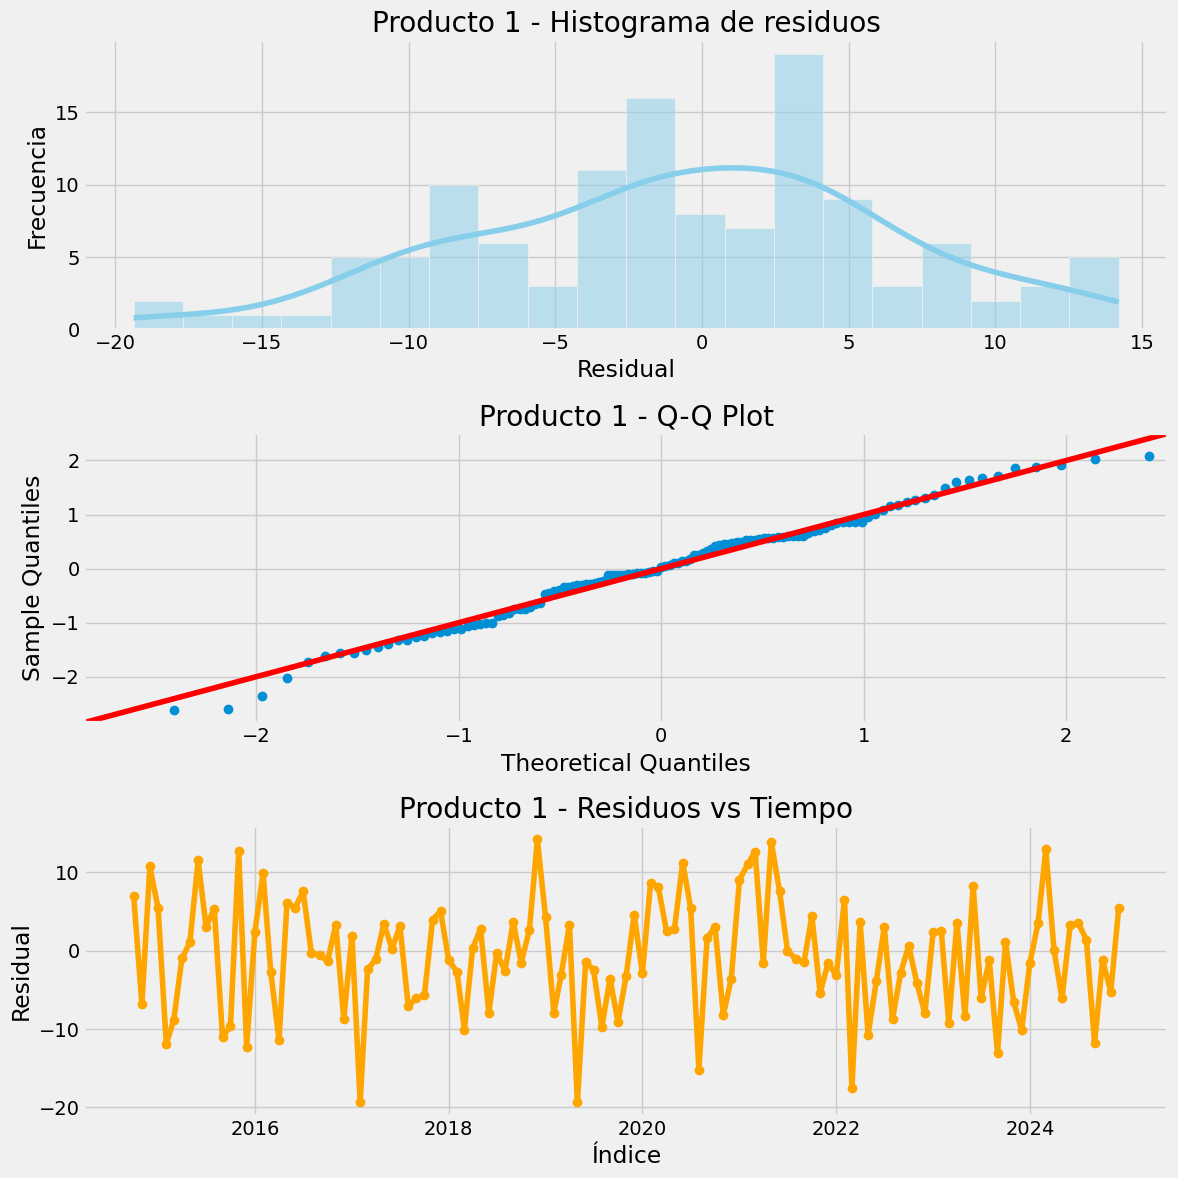

,Test,Statistic,p-value
0,Shapiro-Wilk,0.987449,0.319081
1,Ljung-Box (lag=10),4.522480,0.920715
2,ARCH LM,12.227449,0.270123


In [204]:
def residual_diagnostics(residuals, product_name, arima_order=None):
    """
    Diagnóstico de residuos:
    - Histograma con KDE
    - QQ Plot
    - Residuos en el tiempo
    - Pruebas estadísticas: Shapiro-Wilk, Ljung-Box y ARCH
    """

    # Si es ARIMA, ignorar primeros residuos según p+d
    if arima_order:
        p, d, q = arima_order
        residuals = residuals[d+p:]

    # Si los residuos están vacíos después de eliminar, manejar este caso
    if len(residuals) == 0:
        print(f"Advertencia: No hay residuos suficientes para {product_name} después de eliminar los primeros {d+p} (p+d) residuos. No se pueden realizar diagnósticos.")
        return pd.DataFrame({'Test': ['Shapiro-Wilk', 'Ljung-Box (lag=10)', 'ARCH LM'],
                             'Statistic': [np.nan, np.nan, np.nan],
                             'p-value': [np.nan, np.nan, np.nan]})


    # --- Gráficas ---
    fig, axes = plt.subplots(3, 1, figsize=(12, 12))

    # 1. Histograma + KDE
    sns.histplot(residuals, kde=True, bins=20, ax=axes[0], color='skyblue')
    axes[0].set_title(f'{product_name} - Histograma de residuos')
    axes[0].set_xlabel('Residual')
    axes[0].set_ylabel('Frecuencia')

    # 2. Q-Q plot
    sm.qqplot(residuals, line='45', fit=True, ax=axes[1])
    axes[1].set_title(f'{product_name} - Q-Q Plot')

    # 3. Residuos vs tiempo
    axes[2].plot(residuals, marker='o', linestyle='-', color='orange')
    axes[2].set_title(f'{product_name} - Residuos vs Tiempo')
    axes[2].set_xlabel('Índice')
    axes[2].set_ylabel('Residual')
    axes[2].grid(True)

    plt.tight_layout()
    plt.show()

    # Pruebas estadísticas
    shapiro_stat, shapiro_p = shapiro(residuals)
    ljung_box_result = acorr_ljungbox(residuals, lags=[10], return_df=True)
    arch_test = het_arch(residuals)
    arch_stat, arch_pvalue = arch_test[0], arch_test[1]

    summary = pd.DataFrame({
        'Test': ['Shapiro-Wilk', 'Ljung-Box (lag=10)', 'ARCH LM'],
        'Statistic': [shapiro_stat, ljung_box_result['lb_stat'].values[0], arch_stat],
        'p-value': [shapiro_p, ljung_box_result['lb_pvalue'].values[0], arch_pvalue]
    })

    return summary

# ------------------------
# Re-ajustar modelos para obtener residuos
# ------------------------

# Producto 1 - ARIMA(3,1,2)
# El mejor orden para Producto 1 fue (3,1,2) de resultados_arima['producto1']['best_order']

data.index = pd.to_datetime(data.index)
data = data.asfreq("MS")
model_arima_p1 = ARIMA(data['producto1'], order=(3,1,2))
model_fit_arima_p1 = model_arima_p1.fit()
residuals_p1 = model_fit_arima_p1.resid


# ------------------------
# Diagnóstico
# ------------------------
print("Producto 1 - ARIMA(3,1,2)")
summary_p1 = residual_diagnostics(residuals_p1, 'Producto 1', arima_order=(3,1,2))
display(summary_p1)


De acuerdo a la prueba de Normalidad de Shapiro-Wilk el p-valor es 0.319 siendo mayor que 0.05 y por ende no podemos rechazar la hipótesis nula de normalidad.

En cuanto a autocorrelación verificada con el Test de Ljung-Box, El p-valor es 0.920 mayor que 0.05. Por tal motivo, no podemos rechazar la hipótesis nula de ausencia de autocorrelación.

Por último, se verifica la homocedasticidad con la prueba ARCH obteniendo un p-valor de 0.270, el cual es mayor que 0.05. Por tal motivo, no podemos rechazar la hipótesis nula de homocedasticidad.

Concluyendo entonces que, de acuerdo a los resultados de estos supuestos, el modelo ha logrado capturar adecuadamente la estructura de la serie de tiempo, y sus residuos cumplen con los supuestos de normalidad, no presentan autocorrelación y tienen varianza constante.

Para el producto 2, se realizó el modelo ETS el cual tiene la particularidad de no tener supuestos sobre su funcionamiento, por ende, se procede a no validarlos y realizar el pronóstico solicitado. A continuación, se hace la predicción haciendo uso del data set completo para cada producto


Teniendo en cuenta que, al validar los supuestos del mejor modelo según el RMSE, se toma la decisión de implementar el uso del modelo Arima (3,1,2) para el producto 1 y Holt Winters para el producto 2, el cual tiene la particularidad de no tener supuestos sobre su funcionamiento.

A continuación, se hace la predicción para todo haciendo uso de todo el data set para cada producto

#10. Pronóstico

## Pronostico producto 1


=== Pronóstico Producto 1 ARIMA(3,1,2) ===
     Forecast    Lower 95    Upper 95
0  132.481918  118.278056  146.685779


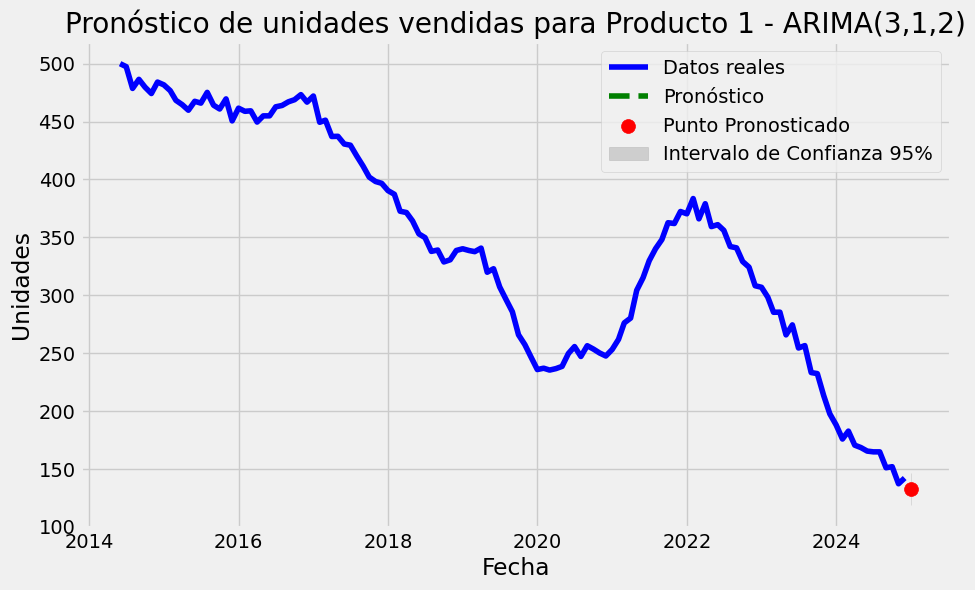

In [205]:
# --- Asegurar frecuencia mensual --- (Usar los datos originales para ARIMA)
# 'data_producto1' contiene la serie original de Producto 1
data_producto1.index = pd.to_datetime(data_producto1.index)
data_producto1 = data_producto1.asfreq("MS")

# --- Ajustar modelo ARIMA(3,1,2) para producto1 ---
# Asegurarse de usar la serie original para el entrenamiento
model_arima_p1 = ARIMA(data_producto1['producto1'], order=(3,1,2))
model_fit = model_arima_p1.fit()

# --- Pronóstico a 1 mes ---
forecast_result = model_fit.get_forecast(steps=1)

forecast_value = forecast_result.predicted_mean.iloc[0]
conf_int = forecast_result.conf_int(alpha=0.05).iloc[0]

# --- Crear tabla ---
forecast_table = pd.DataFrame({
    'Forecast': [forecast_value],
    'Lower 95': [conf_int[0]],
    'Upper 95': [conf_int[1]]
})

print("\n=== Pronóstico Producto 1 ARIMA(3,1,2) ===")
print(forecast_table)

# --- Gráfica ---
plt.figure(figsize=(10, 6))

# Serie real
plt.plot(data_producto1.index, data_producto1['producto1'], label='Datos reales', color='blue')

# Línea del pronóstico
plt.plot(forecast_result.predicted_mean.index,
         forecast_result.predicted_mean,
         label='Pronóstico',
         color='green',
         linestyle='--')

# Punto pronosticado
plt.scatter(forecast_result.predicted_mean.index,
            forecast_value,
            color='red', s=100, zorder=5, label='Punto Pronosticado')

# Intervalo de confianza
plt.fill_between(forecast_result.predicted_mean.index,
                 conf_int[0], conf_int[1],
                 color='gray', alpha=0.3,
                 label='Intervalo de Confianza 95%')

# Configuración
plt.title('Pronóstico de unidades vendidas para Producto 1 - ARIMA(3,1,2)')
plt.xlabel('Fecha')
plt.ylabel('Unidades')
plt.grid(True)
plt.legend()

plt.show()


## Pronostico producto 2

In [206]:
# Asegurar que data y data_producto2 están cargados y con índice de fecha

data_producto2.index = pd.to_datetime(data_producto2.index)
data_producto2 = data_producto2.asfreq("MS")

params_p2 = optimizer_p2.max['params']

error_map = ["add", "mul"]
trend_map = [None, "add", "mul"]
seasonal_map = [None, "add", "mul"]

best_error_p2 = error_map[int(round(params_p2['error']))]
best_trend_p2 = trend_map[int(round(params_p2['trend']))]
best_seasonal_p2 = seasonal_map[int(round(params_p2['seasonal']))]

best_alpha_p2 = params_p2['alpha']
best_beta_p2 = params_p2['beta'] if best_trend_p2 else None
best_gamma_p2 = params_p2['gamma'] if best_seasonal_p2 else None

# Re-instanciar y ajustar el modelo ETS con los mejores parámetros
final_model_p2 = ExponentialSmoothing(
    data_producto2['producto2'],
    trend=best_trend_p2,
    seasonal=best_seasonal_p2,
    seasonal_periods=12 # Asumiendo estacionalidad mensual
).fit(
    smoothing_level=best_alpha_p2,
    smoothing_trend=best_beta_p2,
    smoothing_seasonal=best_gamma_p2
)

residuals_p2 = final_model_p2.resid

print("Modelo ETS óptimo para Producto 2 definido y ajustado.")


Modelo ETS óptimo para Producto 2 definido y ajustado.



===== Pronóstico Final ETS Producto 2 =====
     Forecast   Lower 95%   Upper 95%
0  685.286544  649.478143  721.094945


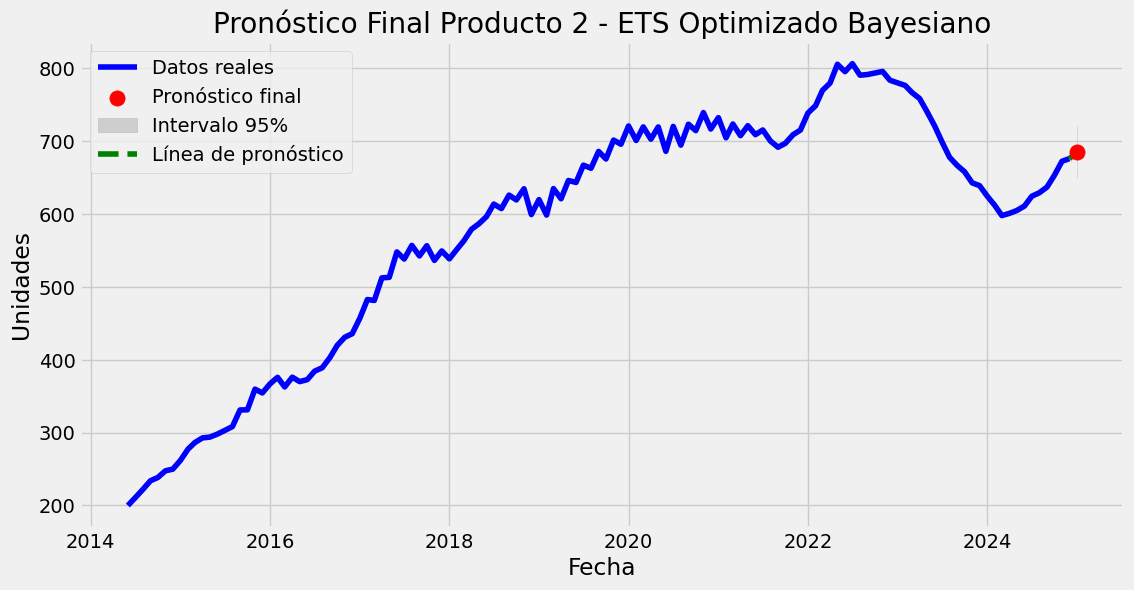

In [207]:
# ============================================================
# 5. PRONÓSTICO FINAL + INTERVALOS DE CONFIANZA 95%
# ============================================================

# Pronóstico
forecast_p2 = final_model_p2.forecast(steps=1).iloc[0]

# Intervalos usando la desviación estándar de los residuos
std_res = residuals_p2.std()

lower_95 = forecast_p2 - 1.96 * std_res
upper_95 = forecast_p2 + 1.96 * std_res

forecast_table_p2 = pd.DataFrame({
    "Forecast": [forecast_p2],
    "Lower 95%": [lower_95],
    "Upper 95%": [upper_95]
})

print("\n===== Pronóstico Final ETS Producto 2 =====")
print(forecast_table_p2)

# ============================================================
# 6. GRAFICAR PRONÓSTICO FINAL CON PUNTO Y INTERVALOS
# ============================================================

plt.figure(figsize=(12, 6))
plt.plot(data_producto2.index, data_producto2['producto2'], label='Datos reales', color='blue')

# Fecha siguiente
next_date = data_producto2.index[-1] + pd.DateOffset(months=1)

# Punto pronosticado
plt.scatter([next_date], [forecast_p2], color='red', s=120, zorder=5, label='Pronóstico final')

# Banda de confianza
plt.fill_between(
    [next_date],
    [lower_95],
    [upper_95],
    color='gray', alpha=0.3, label='Intervalo 95%'
)

# Línea de pronóstico
plt.plot([data_producto2.index[-1], next_date], [data_producto2['producto2'].iloc[-1], forecast_p2], color='green', linestyle='--', label='Línea de pronóstico')

plt.title("Pronóstico Final Producto 2 - ETS Optimizado Bayesiano")
plt.xlabel("Fecha")
plt.ylabel("Unidades")
plt.grid(True)
plt.legend()
plt.show()
